# Reporting Gaps in European COVID-19 Surveillance — Weekly Missingness and Imputation Robustness

Analysis notebook for the PLOS Digital Health manuscript.

WHO records are analysed at the **weekly reporting level** rather than interpreting every daily `NaN` as a missing observation. A week is considered observed for a target if at least one non-missing report for that target exists within the week. `NaN` and reported zero remain distinct.

The notebook performs:
1. weekly aggregation and population normalisation;
2. country-level missingness profiling;
3. extraction of 11 missingness summary features;
4. KMeans-based weekly missingness clustering, benchmarked against alternative clustering algorithms and sensitivity to 8/12/16-week smoothing;
5. Ukraine reporting-gap description;
6. fixed-mask proxy validation using Ukraine's 17-week primary internal case-reporting gap on 12 high-completeness countries;
7. repeated blocked validation using seven high-completeness validation countries and artificial contiguous gaps;
8. comparison of linear interpolation, log-linear interpolation, Kalman local-level smoothing, seasonal decomposition, seasonal-lag baseline, smoothed log-linear interpolation, and Gaussian Process Regression with Matérn-3/2 kernel, depending on validation design;
9. MAE, RMSE, sMAPE, bootstrap intervals and paired method comparisons.


## Setup


In [1]:
import warnings, math, os
warnings.filterwarnings('ignore')
# Datasets here are small; capping the worker count also stops joblib/loky
# from probing physical cores via `wmic`, which no longer exists on
# Windows 11 and otherwise prints a harmless traceback to stderr.
os.environ.setdefault('LOKY_MAX_CPU_COUNT', '4')
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import RobustScaler
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.gaussian_process.kernels import ConstantKernel as C, Matern, WhiteKernel
from scipy.stats import wilcoxon
import statsmodels.api as sm

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


# Unified GPR configuration used in fixed-mask validation, repeated-block
# validation, and the Ukrainian applied reconstruction. Keeping this central
# avoids validating one Gaussian-process model and applying another.
GPR_CONSTANT_VALUE = 1.0
GPR_CONSTANT_BOUNDS = (1e-3, 1e3)
GPR_LENGTH_SCALE = 16.0
GPR_LENGTH_SCALE_BOUNDS = (2, 200)
GPR_WHITE_NOISE_LEVEL = 0.05
GPR_WHITE_NOISE_BOUNDS = (1e-5, 10)
GPR_N_RESTARTS = 1


## 1. Data loading: WHO surveillance data and World Bank population

WHO daily reports (2020–2025) are restricted to the 46-country European panel
and merged with World Bank annual population, including the 2025 estimate.


In [2]:
WHO_FILE = 'WHO-COVID-19-global-daily-data.csv.gz'
POP_FILE = 'API_SP.POP.TOTL_DS2_en_csv_v2_379644.csv'

who = pd.read_csv(WHO_FILE)
who['Date_reported'] = pd.to_datetime(who['Date_reported'])
who = who[(who['Date_reported'] >= '2020-01-01') & (who['Date_reported'] < '2026-01-01')].copy()

# Preserve raw numeric WHO daily corrections before clipping.
# Negative daily corrections can appear when countries revise cumulative counts.
who['New_cases_raw'] = pd.to_numeric(who['New_cases'], errors='coerce')
who['New_deaths_raw'] = pd.to_numeric(who['New_deaths'], errors='coerce')

negative_correction_summary = pd.DataFrame({
    'stream': ['cases', 'deaths'],
    'negative_records': [
        int((who['New_cases_raw'] < 0).sum()),
        int((who['New_deaths_raw'] < 0).sum())
    ],
    'negative_sum': [
        float(who.loc[who['New_cases_raw'] < 0, 'New_cases_raw'].sum()),
        float(who.loc[who['New_deaths_raw'] < 0, 'New_deaths_raw'].sum())
    ],
    'countries_with_negative_records': [
        int(who.loc[who['New_cases_raw'] < 0, 'Country'].nunique()),
        int(who.loc[who['New_deaths_raw'] < 0, 'Country'].nunique())
    ]
})

negative_corrections_by_country = (
    who.assign(
        negative_cases=who['New_cases_raw'].lt(0),
        negative_deaths=who['New_deaths_raw'].lt(0)
    )
    .groupby('Country', as_index=False)
    .agg(
        negative_case_records=('negative_cases', 'sum'),
        negative_death_records=('negative_deaths', 'sum'),
        negative_case_sum=('New_cases_raw', lambda s: float(s[s < 0].sum())),
        negative_death_sum=('New_deaths_raw', lambda s: float(s[s < 0].sum()))
    )
)

who['New_cases'] = who['New_cases_raw'].clip(lower=0)
who['New_deaths'] = who['New_deaths_raw'].clip(lower=0)

print('Negative WHO daily corrections before clipping:')
display(negative_correction_summary)

EUROPE = [
    'Albania','Andorra','Armenia','Austria','Belarus','Belgium','Bosnia and Herzegovina',
    'Bulgaria','Croatia','Cyprus','Czechia','Denmark','Estonia','Finland','France','Georgia',
    'Germany','Greece','Hungary','Iceland','Ireland','Italy','Latvia','Liechtenstein','Lithuania',
    'Luxembourg','Malta','Republic of Moldova','Monaco','Montenegro','Netherlands (Kingdom of the)',
    'North Macedonia','Norway','Poland','Portugal','Romania','Russian Federation','San Marino','Serbia',
    'Slovakia','Slovenia','Spain','Sweden','Switzerland','Ukraine',
    'United Kingdom of Great Britain and Northern Ireland'
]
rename = {
    'Republic of Moldova':'Moldova',
    'Russian Federation':'Russia',
    'United Kingdom of Great Britain and Northern Ireland':'United Kingdom',
    'Netherlands (Kingdom of the)':'Netherlands'
}
who = who[who['Country'].isin(EUROPE)].copy()
who['Country'] = who['Country'].replace(rename)

# World Bank population file has 4 metadata rows
pop = pd.read_csv(POP_FILE, skiprows=4)

pop = pop.rename(columns={'Country Name': 'Country'})

pop['Country'] = pop['Country'].replace({
    'Russian Federation': 'Russia',
    'Slovak Republic': 'Slovakia',
    'Czech Republic': 'Czechia',
    'Moldova': 'Moldova'
})

# 2025 population data are already available in the World Bank file
years = ['2020', '2021', '2022', '2023', '2024', '2025']

pop_long = (
    pop[['Country'] + years]
    .melt(
        id_vars='Country',
        var_name='Year',
        value_name='Population'
    )
)

pop_long['Year'] = pop_long['Year'].astype(int)
pop_long['Population'] = pd.to_numeric(
    pop_long['Population'],
    errors='coerce'
)

print('Population years:', sorted(pop_long['Year'].unique()))
print('Countries with 2025 population:',
      pop_long.loc[
          pop_long['Year'] == 2025,
          'Population'
      ].notna().sum())


Negative WHO daily corrections before clipping:


,stream,negative_records,negative_sum,countries_with_negative_records
0,cases,46,-81708.0,37
1,deaths,30,-6621.0,27


Population years: [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Countries with 2025 population: 264


## 2. Weekly aggregation and the reporting-completeness panel

Daily reports are aggregated to Monday-start weeks. A country-week is **observed** for a
target (cases or deaths) if at least one non-missing daily value was reported
that week; `joint_report` / `joint_missing` combine cases and deaths. The
balanced country×week grid makes every country comparable over the same
calendar span, with weeks absent from the WHO file treated as unreported.


In [3]:
# Weekly aggregation. A target is observed in a week if at least one non-missing value was reported.
who['week'] = who['Date_reported'].dt.to_period('W-SUN').dt.start_time
who['Year'] = who['Date_reported'].dt.year

# Use only complete Monday-start epidemiological weeks in the balanced panel.
# The week starting 2019-12-30 contains only dates from 2020-01-01 onward in
# this file, and the week starting 2025-12-29 is incomplete because the study
# window ends before the full week is observed.
ANALYSIS_WEEK_START = pd.Timestamp('2020-01-06')
ANALYSIS_WEEK_END = pd.Timestamp('2025-12-22')

boundary_week_summary = (
    who.groupby('week')
    .agg(
        first_date=('Date_reported', 'min'),
        last_date=('Date_reported', 'max'),
        n_dates=('Date_reported', 'nunique')
    )
    .reset_index()
)

incomplete_boundary_weeks = boundary_week_summary[
    (boundary_week_summary['week'] < ANALYSIS_WEEK_START)
    |
    (boundary_week_summary['week'] > ANALYSIS_WEEK_END)
].copy()

print('Excluded incomplete boundary weeks:')
display(incomplete_boundary_weeks)

who = who[
    (who['week'] >= ANALYSIS_WEEK_START)
    &
    (who['week'] <= ANALYSIS_WEEK_END)
].copy()

weekly = (who.groupby(['Country','week'], as_index=False)
          .agg(New_cases=('New_cases', lambda s: s.sum(min_count=1)),
               New_deaths=('New_deaths', lambda s: s.sum(min_count=1)),
               case_report=('New_cases', lambda s: int(s.notna().any())),
               death_report=('New_deaths', lambda s: int(s.notna().any()))))
weekly['Year'] = weekly['week'].dt.year
weekly = weekly.merge(pop_long, on=['Country','Year'], how='left')
weekly['cases_per_100k'] = weekly['New_cases'] / weekly['Population'] * 100000
weekly['deaths_per_100k'] = weekly['New_deaths'] / weekly['Population'] * 100000
weekly['joint_report'] = ((weekly['case_report']==1) | (weekly['death_report']==1)).astype(int)
weekly['joint_missing'] = 1 - weekly['joint_report']


# Population merge QA: these countries would have undefined per-capita rates.
pop_missing_by_country = (
    weekly
    .groupby('Country')['Population']
    .apply(lambda s: float(s.isna().mean()))
    .sort_values(ascending=False)
)

print('Countries with any missing population after merge:')
print(
    pop_missing_by_country[pop_missing_by_country > 0]
    .round(3)
    .to_string()
)

print(
    'Slovakia population missing share:',
    round(float(pop_missing_by_country.get('Slovakia', np.nan)), 3)
)

# balanced calendar grid
countries = sorted(weekly['Country'].unique())
weeks = pd.date_range(weekly['week'].min(), weekly['week'].max(), freq='W-MON')
grid = pd.MultiIndex.from_product([countries,weeks], names=['Country','week']).to_frame(index=False)
weekly = grid.merge(weekly, on=['Country','week'], how='left')
for col in ['case_report','death_report','joint_report']:
    weekly[col] = weekly[col].fillna(0).astype(int)
weekly['joint_missing'] = 1-weekly['joint_report']
print('Balanced weekly panel:', weekly.shape, '| weeks:', len(weeks))


Excluded incomplete boundary weeks:


,week,first_date,last_date,n_dates
0,2019-12-30,2020-01-04,2020-01-05,2
313,2025-12-29,2025-12-29,2025-12-31,3


Countries with any missing population after merge:
Series([], )
Slovakia population missing share: 0.0
Balanced weekly panel: (14352, 12) | weeks: 312


## 3. Country-level missingness features

For each country, `make_features()` summarises the weekly `joint_missing`
series (smoothed over a rolling window, `smooth` weeks) into 11 summary
features:

- `mean_missing_*w`, `p95_missing_*w` — average and tail severity of the
  smoothed missingness rate;
- `frac_hi_*w`, `frac_lo_*w` — share of time in high- (> 80%) / low- (< 20%)
  missingness regimes;
- `max_run_hi_weeks`, `n_runs_hi` — length and number of high-missingness
  episodes;
- `cp_jump`, `cp_strength` — size and statistical strength of the single
  largest mean shift (changepoint) in the smoothed series;
- `total_missing_weeks`, `n_missing_transitions`, `recent_missing_rate_52w` —
  overall volume, volatility, and recent (last year) missingness.

The default `smooth=12` (weeks) features are used for the main clustering; an
8/12/16-week sensitivity check follows later in this section.


In [4]:
def run_lengths(mask):
    runs = []
    cur = 0

    for b in np.asarray(mask, bool):
        if b:
            cur += 1
        elif cur:
            runs.append(cur)
            cur = 0

    if cur:
        runs.append(cur)

    return runs


def best_mean_changepoint(x, min_seg=20):
    x = np.asarray(x, float)

    best = (None, 0.0, np.nan, np.nan)

    base = np.nansum(
        (x - np.nanmean(x)) ** 2
    )

    for i in range(min_seg, len(x) - min_seg):

        a = x[:i]
        b = x[i:]

        if (
            np.isfinite(a).sum() < min_seg or
            np.isfinite(b).sum() < min_seg
        ):
            continue

        ma = np.nanmean(a)
        mb = np.nanmean(b)

        sse = (
            np.nansum((a - ma) ** 2) +
            np.nansum((b - mb) ** 2)
        )

        gain = base - sse

        if gain > best[1]:
            best = (i, gain, ma, mb)

    return best


def make_features(df, smooth=12, high=.8, low=.2):
    out = []

    for c, g in df.groupby('Country'):

        g = g.sort_values('week').copy()

        x = g['joint_missing'].astype(float)

        # Rolling missingness rate over the selected window
        xs = (
            x.rolling(
                smooth,
                min_periods=max(2, smooth // 2)
            )
            .mean()
            .to_numpy()
        )

        # Periods with very high missingness
        hi = (
            (xs > high) &
            np.isfinite(xs)
        )

        runs = run_lengths(hi)

        idx, gain, pre, post = best_mean_changepoint(xs)

        var = np.nanvar(xs)

        # Total number of fully missing weeks
        total_missing_weeks = int(
            x.sum()
        )

        # Number of switches between reporting and missing states
        raw = x.to_numpy()

        n_missing_transitions = int(
            np.sum(
                raw[1:] != raw[:-1]
            )
        )

        # Missingness rate during the most recent 52 weeks
        recent = x.tail(52)

        recent_missing_rate_52w = (
            float(recent.mean())
            if len(recent) > 0
            else np.nan
        )

        out.append({

            'Country': c,

            f'mean_missing_{smooth}w':
                np.nanmean(xs),

            f'p95_missing_{smooth}w':
                np.nanpercentile(xs, 95),

            f'frac_hi_{smooth}w':
                np.nanmean(xs > high),

            f'frac_lo_{smooth}w':
                np.nanmean(xs < low),

            'max_run_hi_weeks':
                max(runs) if runs else 0,

            'n_runs_hi':
                len(runs),

            'cp_jump':
                (
                    post - pre
                    if np.isfinite(pre) and np.isfinite(post)
                    else 0
                ),

            'cp_strength':
                (
                    gain /
                    (
                        var *
                        max(np.isfinite(xs).sum(), 1)
                        + 1e-9
                    )
                ),

            'total_missing_weeks':
                total_missing_weeks,

            'n_missing_transitions':
                n_missing_transitions,

            'recent_missing_rate_52w':
                recent_missing_rate_52w
        })

    return pd.DataFrame(out)


features12 = make_features(
    weekly,
    smooth=12
)

features12.head()

,Country,mean_missing_12w,p95_missing_12w,frac_hi_12w,frac_lo_12w,max_run_hi_weeks,n_runs_hi,cp_jump,cp_strength,total_missing_weeks,n_missing_transitions,recent_missing_rate_52w
0,Albania,0.198051,1.000,0.108974,0.695513,20,3,0.312665,0.227729,62,15,0.346154
1,Andorra,0.485069,1.000,0.429487,0.474359,130,2,0.889734,0.895636,154,14,1.000000
2,Armenia,0.042072,0.225,0.012821,0.932692,4,1,-0.405129,0.460381,15,7,0.096154
3,Austria,0.079226,0.735,0.041667,0.871795,10,2,-0.306890,0.107777,24,3,0.000000
4,Belarus,0.541767,1.000,0.461538,0.362179,122,4,0.787642,0.743591,166,17,0.500000


## 4. Benchmarking clustering algorithms on missingness patterns

To avoid committing to one algorithm, a broad grid is benchmarked: k-means,
Ward and average-linkage agglomerative clustering, Gaussian mixtures (4
covariance types), spectral clustering (nearest-neighbour and 5 RBF
bandwidths), DBSCAN (18 eps/min_samples combinations) and OPTICS (27
parameter combinations) — each for `k` (or density parameters) covering a
plausible range. Every solution is scored with Silhouette, Davies–Bouldin,
Calinski–Harabasz and the fraction of noise points, then combined into a single
`composite_score` (mean of the four metrics min–max-normalised to [0, 1], with
Davies–Bouldin and the noise fraction inverted so that higher is always
better). The highest-scoring solution is retained as `clusters12`.


In [5]:
from sklearn.cluster import KMeans, SpectralClustering, DBSCAN, OPTICS
from sklearn.mixture import GaussianMixture


def evaluate_clustering(X, labels):

    labels = np.asarray(labels)

    # noise = -1
    noise_fraction = np.mean(labels == -1)

    non_noise = labels != -1
    X_eval = X[non_noise]
    labels_eval = labels[non_noise]

    n_clusters = len(set(labels_eval))

    # Metrics require at least 2 clusters
    if n_clusters < 2 or len(X_eval) <= n_clusters:
        return {
            'n_clusters': n_clusters,
            'silhouette': np.nan,
            'davies_bouldin': np.nan,
            'calinski_harabasz': np.nan,
            'noise_fraction': noise_fraction
        }

    return {
        'n_clusters': n_clusters,
        'silhouette': silhouette_score(X_eval, labels_eval),
        'davies_bouldin': davies_bouldin_score(X_eval, labels_eval),
        'calinski_harabasz': calinski_harabasz_score(
            X_eval,
            labels_eval
        ),
        'noise_fraction': noise_fraction
    }


def clustering_benchmark(features, k_range=range(2, 9)):

    cols = [
        c for c in features.columns
        if c != 'Country'
    ]

    X = RobustScaler().fit_transform(
        features[cols]
        .replace([np.inf, -np.inf], np.nan)
        .fillna(0)
    )

    rows = []
    labels_store = {}

    # =========================================================
    # K-MEANS
    # =========================================================

    for k in k_range:

        model = KMeans(
            n_clusters=k,
            n_init=200,
            random_state=42
        )

        labels = model.fit_predict(X)

        metrics = evaluate_clustering(X, labels)

        name = f'KMeans_k{k}'

        rows.append({
            'model_id': name,
            'method': 'KMeans',
            'k': k,
            'params': '',
            **metrics
        })

        labels_store[name] = labels


    # =========================================================
    # AGGLOMERATIVE - WARD
    # =========================================================

    for k in k_range:

        model = AgglomerativeClustering(
            n_clusters=k,
            linkage='ward'
        )

        labels = model.fit_predict(X)

        metrics = evaluate_clustering(X, labels)

        name = f'Ward_k{k}'

        rows.append({
            'model_id': name,
            'method': 'Ward',
            'k': k,
            'params': 'linkage=ward',
            **metrics
        })

        labels_store[name] = labels


    # =========================================================
    # AGGLOMERATIVE - AVERAGE
    # =========================================================

    for k in k_range:

        model = AgglomerativeClustering(
            n_clusters=k,
            linkage='average'
        )

        labels = model.fit_predict(X)

        metrics = evaluate_clustering(X, labels)

        name = f'Average_k{k}'

        rows.append({
            'model_id': name,
            'method': 'Agglomerative-average',
            'k': k,
            'params': 'linkage=average',
            **metrics
        })

        labels_store[name] = labels


    # =========================================================
    # GAUSSIAN MIXTURE MODEL
    # =========================================================

    for covariance_type in [
        'full',
        'diag',
        'tied',
        'spherical'
    ]:

        for k in k_range:

            model = GaussianMixture(
                n_components=k,
                covariance_type=covariance_type,
                n_init=40,
                reg_covar=1e-6,
                random_state=42
            )

            labels = model.fit_predict(X)

            metrics = evaluate_clustering(X, labels)

            name = f'GMM_{covariance_type}_k{k}'

            rows.append({
                'model_id': name,
                'method': 'GMM',
                'k': k,
                'params': f'covariance={covariance_type}',
                **metrics
            })

            labels_store[name] = labels


    # =========================================================
    # SPECTRAL - NEAREST NEIGHBORS
    # =========================================================

    for k in k_range:

        model = SpectralClustering(
            n_clusters=k,
            affinity='nearest_neighbors',
            n_neighbors=min(15, len(X)-1),
            assign_labels='kmeans',
            random_state=42
        )

        labels = model.fit_predict(X)

        metrics = evaluate_clustering(X, labels)

        name = f'Spectral_NN_k{k}'

        rows.append({
            'model_id': name,
            'method': 'Spectral-NN',
            'k': k,
            'params': 'nearest_neighbors',
            **metrics
        })

        labels_store[name] = labels


    # =========================================================
    # SPECTRAL - RBF
    # =========================================================

    for gamma in [0.25, 0.5, 1.0, 2.0, 4.0]:

        for k in k_range:

            model = SpectralClustering(
                n_clusters=k,
                affinity='rbf',
                gamma=gamma,
                assign_labels='kmeans',
                random_state=42
            )

            labels = model.fit_predict(X)

            metrics = evaluate_clustering(X, labels)

            name = f'Spectral_RBF_g{gamma}_k{k}'

            rows.append({
                'model_id': name,
                'method': 'Spectral-RBF',
                'k': k,
                'params': f'gamma={gamma}',
                **metrics
            })

            labels_store[name] = labels


    # =========================================================
    # DBSCAN
    # =========================================================

    for eps in [0.4, 0.6, 0.8, 1.0, 1.2, 1.4]:

        for min_samples in [3, 5, 8]:

            model = DBSCAN(
                eps=eps,
                min_samples=min_samples
            )

            labels = model.fit_predict(X)

            metrics = evaluate_clustering(X, labels)

            name = f'DBSCAN_e{eps}_m{min_samples}'

            rows.append({
                'model_id': name,
                'method': 'DBSCAN',
                'k': np.nan,
                'params':
                    f'eps={eps}, min_samples={min_samples}',
                **metrics
            })

            labels_store[name] = labels


    # =========================================================
    # OPTICS
    # =========================================================

    for min_samples in [3, 5, 8]:

        for xi in [0.03, 0.05, 0.08]:

            for min_cluster_size in [0.03, 0.05, 0.08]:

                model = OPTICS(
                    min_samples=min_samples,
                    xi=xi,
                    min_cluster_size=min_cluster_size
                )

                labels = model.fit_predict(X)

                metrics = evaluate_clustering(X, labels)

                name = (
                    f'OPTICS_m{min_samples}_'
                    f'xi{xi}_c{min_cluster_size}'
                )

                rows.append({
                    'model_id': name,
                    'method': 'OPTICS',
                    'k': np.nan,
                    'params':
                        f'min_samples={min_samples}, '
                        f'xi={xi}, '
                        f'min_cluster_size={min_cluster_size}',
                    **metrics
                })

                labels_store[name] = labels


    results = pd.DataFrame(rows)


    # =========================================================
    # COMPOSITE SCORE
    # =========================================================

    valid = results[
        results['n_clusters'] >= 2
    ].copy()

    def normalize_positive(x):
        if x.max() == x.min():
            return pd.Series(
                np.ones(len(x)),
                index=x.index
            )
        return (
            (x - x.min()) /
            (x.max() - x.min())
        )

    valid['sil_norm'] = normalize_positive(
        valid['silhouette']
    )

    valid['ch_norm'] = normalize_positive(
        valid['calinski_harabasz']
    )

    # lower DB is better
    db_norm = normalize_positive(
        valid['davies_bouldin']
    )

    valid['db_norm'] = 1 - db_norm

    # lower noise is better
    valid['noise_norm'] = (
        1 - valid['noise_fraction']
    )

    valid['composite_score'] = (
        valid['sil_norm'] +
        valid['ch_norm'] +
        valid['db_norm'] +
        valid['noise_norm']
    ) / 4


    valid = valid.sort_values(
        'composite_score',
        ascending=False
    )

    best = valid.iloc[0]

    best_model_id = best['model_id']

    best_labels = labels_store[
        best_model_id
    ]


    clusters = features[['Country']].copy()

    clusters['cluster'] = best_labels


    return (
        valid,
        best,
        clusters,
        labels_store
    )

In [6]:
results12, best12, clusters12, labels_store12 = (
    clustering_benchmark(
        features12,
        k_range=range(2, 9)
    )
)

print(
    results12[
        [
            'method',
            'k',
            'params',
            'n_clusters',
            'silhouette',
            'davies_bouldin',
            'calinski_harabasz',
            'noise_fraction',
            'composite_score'
        ]
    ]
    .head(20)
    .to_string(index=False)
)

               method   k          params  n_clusters  silhouette  davies_bouldin  calinski_harabasz  noise_fraction  composite_score
               KMeans 2.0                           2    0.723125        0.508172         114.662779             0.0         0.959712
                  GMM 2.0 covariance=tied           2    0.723125        0.508172         114.662779             0.0         0.959712
                  GMM 2.0 covariance=diag           2    0.723125        0.508172         114.662779             0.0         0.959712
                  GMM 2.0 covariance=full           2    0.723125        0.508172         114.662779             0.0         0.959712
Agglomerative-average 2.0 linkage=average           2    0.721667        0.406929          97.723149             0.0         0.936728
         Spectral-RBF 2.0       gamma=2.0           2    0.721667        0.406929          97.723149             0.0         0.936728
         Spectral-RBF 2.0      gamma=0.25           2    0.721

In [7]:
top4 = results12[
    [
        'model_id',
        'method',
        'k',
        'params',
        'n_clusters',
        'silhouette',
        'davies_bouldin',
        'calinski_harabasz',
        'noise_fraction',
        'composite_score'
    ]
].head(10).copy()


# Add cluster sizes for each solution

cluster_sizes_list = []

for model_id in top4['model_id']:

    labels = labels_store12[model_id]

    sizes = (
        pd.Series(labels)
        .value_counts()
        .sort_index()
        .to_dict()
    )

    # Format as: 0:40, 1:6
    sizes_str = ', '.join(
        [f'{cluster}:{count}' for cluster, count in sizes.items()]
    )

    cluster_sizes_list.append(sizes_str)


top4['cluster_sizes'] = cluster_sizes_list


print('\nTop clustering solutions:')
print(
    top4[
        [
            'method',
            'k',
            'params',
            'n_clusters',
            'cluster_sizes',
            'silhouette',
            'davies_bouldin',
            'calinski_harabasz',
            'noise_fraction',
            'composite_score'
        ]
    ].to_string(index=False)
)


Top clustering solutions:
               method   k          params  n_clusters cluster_sizes  silhouette  davies_bouldin  calinski_harabasz  noise_fraction  composite_score
               KMeans 2.0                           2     0:38, 1:8    0.723125        0.508172         114.662779             0.0         0.959712
                  GMM 2.0 covariance=tied           2     0:38, 1:8    0.723125        0.508172         114.662779             0.0         0.959712
                  GMM 2.0 covariance=diag           2     0:38, 1:8    0.723125        0.508172         114.662779             0.0         0.959712
                  GMM 2.0 covariance=full           2     0:38, 1:8    0.723125        0.508172         114.662779             0.0         0.959712
Agglomerative-average 2.0 linkage=average           2     0:40, 1:6    0.721667        0.406929          97.723149             0.0         0.936728
         Spectral-RBF 2.0       gamma=2.0           2     0:40, 1:6    0.721667      

### Selecting Ukraine's cluster


In [8]:
ua_cl = int(
    clusters12.loc[
        clusters12['Country'].eq('Ukraine'),
        'cluster'
    ].iloc[0]
)

ukraine_members = (
    clusters12.loc[
        clusters12['cluster'].eq(ua_cl),
        'Country'
    ]
    .sort_values()
    .tolist()
)

print('\nUkraine cluster:', ua_cl)
print('Number of countries:', len(ukraine_members))
print('Ukraine cluster members:')
print(ukraine_members)


Ukraine cluster: 0
Number of countries: 38
Ukraine cluster members:
['Albania', 'Armenia', 'Austria', 'Belgium', 'Bosnia and Herzegovina', 'Bulgaria', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Estonia', 'Finland', 'France', 'Georgia', 'Germany', 'Greece', 'Hungary', 'Iceland', 'Ireland', 'Italy', 'Latvia', 'Liechtenstein', 'Lithuania', 'Luxembourg', 'Malta', 'Moldova', 'Netherlands', 'Norway', 'Poland', 'Portugal', 'Romania', 'Serbia', 'Slovakia', 'Slovenia', 'Sweden', 'Switzerland', 'Ukraine', 'United Kingdom']


### Cluster-level feature profiles

This diagnostic table makes the two-cluster solution interpretable. It reports the countries in the smaller cluster and cluster-level medians of the missingness features used for KMeans. The aim is to show whether the split is merely a one-dimensional completeness threshold or a broader reporting-continuity profile.


In [9]:
cluster_feature_profile = features12.copy()
cluster_feature_profile['cluster'] = labels_store12['KMeans_k2']

cluster_sizes = (
    cluster_feature_profile['cluster']
    .value_counts()
    .sort_index()
)

smaller_cluster = int(cluster_sizes.idxmin())
smaller_cluster_countries = (
    cluster_feature_profile.loc[
        cluster_feature_profile['cluster'].eq(smaller_cluster),
        'Country'
    ]
    .sort_values()
    .tolist()
)

print('KMeans cluster sizes:')
print(cluster_sizes.to_string())
print('\nCountries in the smaller KMeans cluster:')
print(smaller_cluster_countries)

profile_cols = [
    'mean_missing_12w',
    'p95_missing_12w',
    'frac_hi_12w',
    'frac_lo_12w',
    'max_run_hi_weeks',
    'n_runs_hi',
    'cp_jump',
    'cp_strength',
    'total_missing_weeks',
    'n_missing_transitions',
    'recent_missing_rate_52w'
]

cluster_feature_summary = (
    cluster_feature_profile
    .groupby('cluster')[profile_cols]
    .median()
    .round(3)
)

print('\nCluster-level median feature profile:')
display(cluster_feature_summary)


KMeans cluster sizes:
cluster
0    38
1     8

Countries in the smaller KMeans cluster:
['Andorra', 'Belarus', 'Monaco', 'Montenegro', 'North Macedonia', 'Russia', 'San Marino', 'Spain']

Cluster-level median feature profile:


,mean_missing_12w,p95_missing_12w,frac_hi_12w,frac_lo_12w,max_run_hi_weeks,n_runs_hi,cp_jump,cp_strength,total_missing_weeks,n_missing_transitions,recent_missing_rate_52w
cluster,,,,,,,,,,,
0,0.032,0.125,0.013,0.946,4.0,1.0,-0.366,0.468,9.5,3.0,0.000
1,0.397,1.000,0.329,0.522,100.0,2.0,0.878,0.848,127.0,14.0,0.913


### Agreement between clustering algorithms

Pairwise ARI/NMI between the k=2 solutions of the four best-performing
algorithms (k-means, Ward, GMM, spectral-RBF).


In [10]:
from sklearn.metrics import adjusted_rand_score, normalized_mutual_info_score

# Prepare scaled feature matrix
cols = [c for c in features12.columns if c != 'Country']

X = RobustScaler().fit_transform(
    features12[cols]
    .replace([np.inf, -np.inf], np.nan)
    .fillna(0)
)

# KMeans
labels_kmeans = KMeans(
    n_clusters=2,
    n_init=200,
    random_state=42
).fit_predict(X)

# Ward
labels_ward = AgglomerativeClustering(
    n_clusters=2,
    linkage='ward'
).fit_predict(X)

# GMM
labels_gmm = GaussianMixture(
    n_components=2,
    covariance_type='full',
    n_init=40,
    reg_covar=1e-6,
    random_state=42
).fit_predict(X)

# Spectral RBF
labels_spectral = SpectralClustering(
    n_clusters=2,
    affinity='rbf',
    gamma=1.0,
    assign_labels='kmeans',
    random_state=42
).fit_predict(X)

method_labels = {
    'KMeans': labels_kmeans,
    'Ward': labels_ward,
    'GMM': labels_gmm,
    'Spectral-RBF': labels_spectral
}

# Pairwise ARI / NMI
comparison_rows = []

methods = list(method_labels.keys())

for i in range(len(methods)):
    for j in range(i + 1, len(methods)):

        m1 = methods[i]
        m2 = methods[j]

        comparison_rows.append({
            'method_1': m1,
            'method_2': m2,
            'ARI': adjusted_rand_score(
                method_labels[m1],
                method_labels[m2]
            ),
            'NMI': normalized_mutual_info_score(
                method_labels[m1],
                method_labels[m2]
            )
        })

method_agreement = pd.DataFrame(comparison_rows)

print('\nAgreement between clustering methods:')
print(method_agreement.to_string(index=False))


Agreement between clustering methods:
method_1     method_2      ARI      NMI
  KMeans         Ward 0.898048 0.823519
  KMeans          GMM 1.000000 1.000000
  KMeans Spectral-RBF 0.781646 0.681578
    Ward          GMM 0.898048 0.823519
    Ward Spectral-RBF 0.691804 0.595958
     GMM Spectral-RBF 0.781646 0.681578


In [11]:
comparison = features12[['Country']].copy()

comparison['KMeans'] = labels_kmeans
comparison['Ward'] = labels_ward
comparison['GMM'] = labels_gmm
comparison['Spectral_RBF'] = labels_spectral

print('\nCluster sizes:')

for col in ['KMeans', 'Ward', 'GMM', 'Spectral_RBF']:
    print(f'\n{col}:')
    print(
        comparison[col]
        .value_counts()
        .sort_index()
        .to_string()
    )

print('\nCountries with different KMeans vs Ward assignment:')

diff_kw = comparison[
    comparison['KMeans'] != comparison['Ward']
]

print(
    diff_kw[
        ['Country', 'KMeans', 'Ward']
    ].to_string(index=False)
)


Cluster sizes:

KMeans:
KMeans
0    38
1     8

Ward:
Ward
0     9
1    37

GMM:
GMM
0    38
1     8

Spectral_RBF:
Spectral_RBF
0    40
1     6

Countries with different KMeans vs Ward assignment:
               Country  KMeans  Ward
               Albania       0     1
               Andorra       1     0
               Armenia       0     1
               Austria       0     1
               Belarus       1     0
               Belgium       0     1
Bosnia and Herzegovina       0     1
              Bulgaria       0     1
               Croatia       0     1
                Cyprus       0     1
               Czechia       0     1
               Denmark       0     1
               Estonia       0     1
               Finland       0     1
                France       0     1
               Georgia       0     1
               Germany       0     1
                Greece       0     1
               Hungary       0     1
               Iceland       0     1
               Ireland  

### Sensitivity to the smoothing window

Repeats the k-means k=2 solution with `smooth` set to 8, 12 and 16 weeks, to
check that the two-cluster split is not an artefact of the specific smoothing
window used for the main analysis.


In [12]:
# Sensitivity to smoothing window for primary KMeans k=2 solution

sens = []
assignments = {}

for w in [8, 12, 16]:

    f = make_features(
        weekly,
        smooth=w
    )

    cols = [
        c for c in f.columns
        if c != 'Country'
    ]

    X = RobustScaler().fit_transform(
        f[cols]
        .replace([np.inf, -np.inf], np.nan)
        .fillna(0)
    )

    labels = KMeans(
        n_clusters=2,
        n_init=200,
        random_state=42
    ).fit_predict(X)

    sil = silhouette_score(
        X,
        labels
    )

    db = davies_bouldin_score(
        X,
        labels
    )

    ch = calinski_harabasz_score(
        X,
        labels
    )

    cluster_sizes = (
        pd.Series(labels)
        .value_counts()
        .sort_index()
        .to_dict()
    )

    sens.append({
        'window_weeks': w,
        'k': 2,
        'silhouette': sil,
        'davies_bouldin': db,
        'calinski_harabasz': ch,
        'cluster_0_n': cluster_sizes.get(0, 0),
        'cluster_1_n': cluster_sizes.get(1, 0)
    })

    tmp = f[['Country']].copy()
    tmp['cluster'] = labels

    assignments[w] = (
        tmp.set_index('Country')['cluster']
    )


sensitivity = pd.DataFrame(sens)

print('\nKMeans k=2 sensitivity to smoothing window:')
print(
    sensitivity.to_string(index=False)
)


KMeans k=2 sensitivity to smoothing window:
 window_weeks  k  silhouette  davies_bouldin  calinski_harabasz  cluster_0_n  cluster_1_n
            8  2    0.724624        0.502904         119.234781           38            8
           12  2    0.723125        0.508172         114.662779           38            8
           16  2    0.711264        0.526078         106.623288           38            8


In [13]:
window_agreement = []

windows = [8, 12, 16]

for i in range(len(windows)):
    for j in range(i + 1, len(windows)):

        w1 = windows[i]
        w2 = windows[j]

        common = (
            assignments[w1]
            .index
            .intersection(assignments[w2].index)
        )

        lab1 = assignments[w1].loc[common]
        lab2 = assignments[w2].loc[common]

        window_agreement.append({
            'window_1': w1,
            'window_2': w2,
            'ARI': adjusted_rand_score(
                lab1,
                lab2
            ),
            'NMI': normalized_mutual_info_score(
                lab1,
                lab2
            )
        })

window_agreement = pd.DataFrame(
    window_agreement
)

print('\nAgreement across smoothing windows:')
print(
    window_agreement.to_string(index=False)
)


Agreement across smoothing windows:
 window_1  window_2  ARI  NMI
        8        12  1.0  1.0
        8        16  1.0  1.0
       12        16  1.0  1.0


## 5. Ukraine's reporting gaps


In [14]:

# Ukraine weekly reporting gaps
ua=weekly[weekly.Country.eq('Ukraine')].sort_values('week').copy()
ua_gap=ua['joint_missing'].eq(1)
print('Ukraine weeks in panel:', len(ua))
print('Weeks without either case or death report:', int(ua_gap.sum()))
if ua_gap.any():
    print('First gap week:', ua.loc[ua_gap,'week'].min().date())
    print('Last gap week :', ua.loc[ua_gap,'week'].max().date())
print('Case-unreported weeks:', int((ua.case_report==0).sum()))
print('Death-unreported weeks:', int((ua.death_report==0).sum()))


Ukraine weeks in panel: 312
Weeks without either case or death report: 26
First gap week: 2020-01-06
Last gap week : 2023-10-23
Case-unreported weeks: 26
Death-unreported weeks: 40


In [15]:
# Ukraine-derived primary internal case-reporting gap mask.
# The proxy validation evaluates the same bounded 17-week gap that is used
# as the primary applied reconstruction target. Boundary gaps at the start of
# the Ukraine series are not included because they do not have left-side
# observed context and are not reconstructed in the manuscript.

PRIMARY_CASE_GAP_START = pd.Timestamp("2023-07-03")
PRIMARY_CASE_GAP_END = pd.Timestamp("2023-10-23")

ua_mask = (
    (weeks >= PRIMARY_CASE_GAP_START)
    &
    (weeks <= PRIMARY_CASE_GAP_END)
)

print(
    "Primary internal case-gap mask size:",
    int(ua_mask.sum()),
    "of",
    len(ua_mask),
    "weeks"
)

# Keep the complete Ukraine missingness calendar for descriptive checks only.
ua_all_missing_mask = (
    ua.set_index('week')['joint_missing']
    .reindex(weeks)
    .fillna(1)
    .astype(bool)
    .to_numpy()
)

print(
    "All Ukraine joint-missing weeks (descriptive):",
    int(ua_all_missing_mask.sum())
)

# Identify Ukraine's KMeans cluster
kmeans_labels = labels_store12['KMeans_k2']
clusters_kmeans = features12[['Country']].copy()
clusters_kmeans['cluster'] = kmeans_labels
ua_cluster = int(
    clusters_kmeans.loc[
        clusters_kmeans['Country'].eq('Ukraine'),
        'cluster'
    ].iloc[0]
)

same_cluster = clusters_kmeans.loc[
    clusters_kmeans['cluster'].eq(ua_cluster),
    'Country'
].tolist()

# Explicit alias used by the repeated-block validation section.
ukraine_cluster_countries = same_cluster

# Completeness among same-cluster countries excluding Ukraine
complete = (
    weekly[weekly['Country'].isin([c for c in same_cluster if c != 'Ukraine'])]
    .groupby('Country')['joint_missing']
    .apply(lambda x: 1 - x.mean())
    .sort_values(ascending=False)
)

comparators = complete.head(12).index.tolist()

print('Ukraine cluster:', ua_cluster)
print('Countries in Ukraine cluster:', same_cluster)
print('Proxy-validation countries from Ukraine cluster:', comparators)
print('Reporting completeness:')
print(complete.head(12).round(3).to_string())


Primary internal case-gap mask size: 17 of 312 weeks
All Ukraine joint-missing weeks (descriptive): 26
Ukraine cluster: 0
Countries in Ukraine cluster: ['Albania', 'Armenia', 'Austria', 'Belgium', 'Bosnia and Herzegovina', 'Bulgaria', 'Croatia', 'Cyprus', 'Czechia', 'Denmark', 'Estonia', 'Finland', 'France', 'Georgia', 'Germany', 'Greece', 'Hungary', 'Iceland', 'Ireland', 'Italy', 'Latvia', 'Liechtenstein', 'Lithuania', 'Luxembourg', 'Malta', 'Moldova', 'Netherlands', 'Norway', 'Poland', 'Portugal', 'Romania', 'Serbia', 'Slovakia', 'Slovenia', 'Sweden', 'Switzerland', 'Ukraine', 'United Kingdom']
Proxy-validation countries from Ukraine cluster: ['United Kingdom', 'Portugal', 'Sweden', 'Croatia', 'Belgium', 'Luxembourg', 'Greece', 'Switzerland', 'Romania', 'Malta', 'Poland', 'Ireland']
Reporting completeness:
Country
United Kingdom    0.990
Portugal          0.981
Sweden            0.981
Croatia           0.978
Belgium           0.978
Luxembourg        0.978
Greece            0.978
Swit

## 6. Proxy validation: applying Ukraine's primary internal case-gap mask to comparator countries

Ukraine's own weekly missingness mask cannot validate a reconstruction of
Ukraine's own gaps, because the true values are unknown. The proxy validation
therefore applies the **17-week primary internal case-reporting gap** (3 July to
23 October 2023) to the 12 countries in Ukraine's cluster with the highest
reporting completeness. Their known values are hidden at those weeks, five
candidate reconstruction methods are fitted on what remains, and each method's
predictions are scored against the hidden ground truth. The fixed-mask seasonal
method is **seasonal decomposition** (trend plus seasonal component), not the
seasonal-lag baseline used later in the repeated blocked validation. Boundary
gaps at the start of the Ukraine series are excluded from this validation
because they are not reconstructed in the applied analysis.


In [16]:
def linear_interp(y):
    s = pd.Series(np.asarray(y, float))

    return (
        s.interpolate(
            method='linear',
            limit_direction='both'
        )
        .to_numpy()
    )


def linear_log(y):
    s = pd.Series(
        np.log1p(
            np.clip(
                np.asarray(y, float),
                0,
                None
            )
        )
    )

    z = (
        s.interpolate(
            'linear',
            limit_direction='both'
        )
        .to_numpy()
    )

    return np.clip(
        np.expm1(z),
        0,
        None
    )


def kalman_local(y):
    z = pd.Series(
        np.log1p(
            np.clip(
                np.asarray(y, float),
                0,
                None
            )
        )
    )

    try:
        mod = sm.tsa.UnobservedComponents(
            z,
            level='local level'
        )

        res = mod.fit(
            disp=False
        )

        # Use the smoothed latent level, not one-step-ahead predictions.
        # This lets observations after an internal gap inform the reconstructed
        # states inside the gap.
        pred = np.asarray(
            res.smoothed_state[0],
            float
        )

        return np.clip(
            np.expm1(pred),
            0,
            None
        )

    except Exception:
        return linear_log(y)


def seasonal_decomposition(y):
    arr = np.asarray(
        y,
        float
    )

    z = pd.Series(
        np.log1p(
            np.clip(
                arr,
                0,
                None
            )
        )
    )

    z0 = z.interpolate(
        'linear',
        limit_direction='both'
    )

    period = (
        52
        if len(z0) >= 104
        else 13
    )

    try:
        dec = sm.tsa.seasonal_decompose(
            z0,
            model='additive',
            period=period,
            extrapolate_trend='freq'
        )

        fit = (
            dec.trend +
            dec.seasonal
        ).interpolate(
            'linear',
            limit_direction='both'
        )

        out = z.copy()

        out[out.isna()] = fit[
            out.isna()
        ]

        out = out.interpolate(
            'linear',
            limit_direction='both'
        )

        return np.clip(
            np.expm1(
                out.to_numpy()
            ),
            0,
            None
        )

    except Exception:
        return linear_log(y)


def gpr_matern32(y):
    y = np.asarray(
        y,
        float
    )

    x = np.arange(
        len(y),
        dtype=float
    ).reshape(-1, 1)

    obs = np.isfinite(y)

    if obs.sum() < 20:
        return linear_log(y)

    z = np.log1p(
        np.clip(
            y,
            0,
            None
        )
    )

    kernel = (
        C(
            GPR_CONSTANT_VALUE,
            GPR_CONSTANT_BOUNDS
        )
        *
        Matern(
            length_scale=GPR_LENGTH_SCALE,
            length_scale_bounds=GPR_LENGTH_SCALE_BOUNDS,
            nu=1.5
        )
        +
        WhiteKernel(
            GPR_WHITE_NOISE_LEVEL,
            GPR_WHITE_NOISE_BOUNDS
        )
    )

    gp = GaussianProcessRegressor(
        kernel=kernel,
        normalize_y=True,
        random_state=RANDOM_STATE,
        n_restarts_optimizer=GPR_N_RESTARTS
    )

    gp.fit(
        x[obs],
        z[obs]
    )

    return np.clip(
        np.expm1(
            gp.predict(x)
        ),
        0,
        None
    )


MODELS = {
    'linear': linear_interp,
    'log-linear': linear_log,
    'Kalman': kalman_local,
    'seasonal decomposition': seasonal_decomposition,
    'GPR Matern-3/2': gpr_matern32
}


def scores(y_true, y_hat, mask):

    y_true = np.asarray(y_true, dtype=float)
    y_hat = np.asarray(y_hat, dtype=float)
    mask = np.asarray(mask, dtype=bool)

    m = (
        mask
        & np.isfinite(y_true)
        & np.isfinite(y_hat)
    )

    if m.sum() == 0:
        return dict(
            n=0,
            mae=np.nan,
            rmse=np.nan,
            smape=np.nan,
            rmse_log1p=np.nan,
            mase=np.nan
        )

    e = (
        y_hat[m] -
        y_true[m]
    )

    z_true = np.log1p(
        np.clip(y_true[m], 0, None)
    )
    z_hat = np.log1p(
        np.clip(y_hat[m], 0, None)
    )

    finite_series = y_true[np.isfinite(y_true)]
    diffs = np.abs(np.diff(finite_series))
    denom = float(np.nanmean(diffs)) if len(diffs) else np.nan
    if (not np.isfinite(denom)) or denom <= 1e-12:
        mase = np.nan
    else:
        mase = float(np.mean(np.abs(e)) / denom)

    return dict(
        n=int(m.sum()),

        mae=float(
            np.mean(
                np.abs(e)
            )
        ),

        rmse=float(
            np.sqrt(
                np.mean(
                    e ** 2
                )
            )
        ),

        smape=float(
            np.mean(
                2 * np.abs(e) /
                (
                    np.abs(y_true[m]) +
                    np.abs(y_hat[m]) +
                    1e-9
                )
            ) * 100
        ),

        rmse_log1p=float(
            np.sqrt(
                np.mean(
                    (z_hat - z_true) ** 2
                )
            )
        ),

        mase=mase
    )


In [17]:
# Proxy validation on cases and deaths per 100k
rows = []

for target in ['cases_per_100k', 'deaths_per_100k']:
    for c in comparators:
        s = (
            weekly.loc[weekly.Country.eq(c), ['week', target]]
            .set_index('week')[target]
            .reindex(weeks)
        )

        truth = s.to_numpy(float)
        eval_mask = ua_mask & np.isfinite(truth)

        if eval_mask.sum() < 10:
            continue

        masked = truth.copy()
        masked[ua_mask] = np.nan

        for name, fn in MODELS.items():
            try:
                pred = fn(masked)
                rows.append({
                    'target': target,
                    'Country': c,
                    'method': name,
                    **scores(truth, pred, eval_mask)
                })
            except Exception as e:
                rows.append({
                    'target': target,
                    'Country': c,
                    'method': name,
                    'n': 0,
                    'mae': np.nan,
                    'rmse': np.nan,
                    'smape': np.nan,
                    'rmse_log1p': np.nan,
                    'mase': np.nan,
                    'error': str(e)[:120]
                })

results = pd.DataFrame(rows)

summary = (
    results
    .groupby(['target', 'method'])[
        ['mae', 'rmse', 'smape', 'rmse_log1p', 'mase']
    ]
    .median()
    .reset_index()
    .sort_values(['target', 'rmse'])
)

print(summary.to_string(index=False))


         target                 method      mae      rmse     smape  rmse_log1p     mase
 cases_per_100k seasonal decomposition 6.850381  8.176879 64.670285    0.715578 0.275520
 cases_per_100k         GPR Matern-3/2 7.376083  8.806010 53.377745    0.536029 0.219931
 cases_per_100k                 linear 8.670595 10.084776 67.623668    0.701860 0.279176
 cases_per_100k             log-linear 8.169747 10.135880 72.421392    0.729000 0.292894
 cases_per_100k                 Kalman 8.169747 10.135880 72.421392    0.729000 0.292894
deaths_per_100k                 Kalman 0.112340  0.132387 65.254459    0.105859 0.315071
deaths_per_100k         GPR Matern-3/2 0.115639  0.134229 67.387437    0.101033 0.414742
deaths_per_100k             log-linear 0.119345  0.146426 65.254459    0.117772 0.332237
deaths_per_100k                 linear 0.123283  0.149986 66.590058    0.121861 0.344362
deaths_per_100k seasonal decomposition 0.142067  0.166774 86.240282    0.125449 0.472309


In [18]:

# Paired Wilcoxon tests: GPR vs log-linear for RMSE across comparator countries
for target in ['cases_per_100k','deaths_per_100k']:
    p=results[results.target.eq(target)].pivot(index='Country',columns='method',values='rmse')
    p=p[['GPR Matern-3/2','log-linear']].dropna()
    if len(p)>=5:
        stat,pval=wilcoxon(p['GPR Matern-3/2'],p['log-linear'],alternative='two-sided')
        print(target, '| n =',len(p),'| median GPR =',round(p['GPR Matern-3/2'].median(),4),
              '| median log-linear =',round(p['log-linear'].median(),4),'| Wilcoxon p =',round(pval,6))


cases_per_100k | n = 12 | median GPR = 8.806 | median log-linear = 10.1359 | Wilcoxon p = 0.009277
deaths_per_100k | n = 10 | median GPR = 0.1342 | median log-linear = 0.1464 | Wilcoxon p = 0.556641


In [19]:

# Bootstrap 95% confidence intervals for the median RMSE across countries
rng=np.random.default_rng(RANDOM_STATE)
def bootstrap_median_ci(x,B=5000):
    x=np.asarray(pd.Series(x).dropna(),float)
    if len(x)==0: return (np.nan,np.nan)
    meds=np.array([np.median(rng.choice(x,size=len(x),replace=True)) for _ in range(B)])
    return tuple(np.percentile(meds,[2.5,97.5]))

ci_rows=[]
for (target,method),g in results.groupby(['target','method']):
    lo,hi=bootstrap_median_ci(g['rmse'])
    ci_rows.append({'target':target,'method':method,'median_rmse':g['rmse'].median(),'ci95_low':lo,'ci95_high':hi,'n_countries':g['rmse'].notna().sum()})
ci_table=pd.DataFrame(ci_rows).sort_values(['target','median_rmse'])
print(ci_table.to_string(index=False))


         target                 method  median_rmse  ci95_low  ci95_high  n_countries
 cases_per_100k seasonal decomposition     8.176879  5.456062  19.425547           12
 cases_per_100k         GPR Matern-3/2     8.806010  6.128114  17.451843           12
 cases_per_100k                 linear    10.084776  7.591456  19.272969           12
 cases_per_100k             log-linear    10.135880  7.120908  18.534429           12
 cases_per_100k                 Kalman    10.135880  7.120908  18.534429           12
deaths_per_100k                 Kalman     0.132387  0.031865   0.225778           10
deaths_per_100k         GPR Matern-3/2     0.134229  0.073481   0.223827           10
deaths_per_100k             log-linear     0.146426  0.031865   0.225778           10
deaths_per_100k                 linear     0.149986  0.047149   0.225778           10
deaths_per_100k seasonal decomposition     0.166774  0.085426   0.223934           10


In [20]:
from itertools import combinations
from statsmodels.stats.multitest import multipletests

pairwise_rows = []

for target in ['cases_per_100k', 'deaths_per_100k']:

    # Country x Method table for RMSE
    p = (
        results[results['target'].eq(target)]
        .pivot(
            index='Country',
            columns='method',
            values='rmse'
        )
    )

    methods = p.columns.tolist()

    for m1, m2 in combinations(methods, 2):

        pair = p[[m1, m2]].dropna()

        if len(pair) < 5:
            continue

        x = pair[m1]
        y = pair[m2]

        # Avoid Wilcoxon failure if all paired differences are zero
        if np.allclose(x - y, 0):
            stat = 0.0
            pval = 1.0
        else:
            stat, pval = wilcoxon(
                x,
                y,
                alternative='two-sided'
            )

        pairwise_rows.append({
            'target': target,
            'method_1': m1,
            'method_2': m2,
            'n_pairs': len(pair),
            'median_rmse_1': x.median(),
            'median_rmse_2': y.median(),
            'median_difference':
                np.median(x - y),
            'wilcoxon_stat': stat,
            'p_value': pval
        })


pairwise_wilcoxon = pd.DataFrame(pairwise_rows)


# Benjamini-Hochberg FDR correction separately for each target

pairwise_wilcoxon['p_fdr'] = np.nan
pairwise_wilcoxon['significant_fdr'] = False

for target in pairwise_wilcoxon['target'].unique():

    mask = pairwise_wilcoxon['target'].eq(target)

    reject, pvals_corrected, _, _ = multipletests(
        pairwise_wilcoxon.loc[mask, 'p_value'],
        alpha=0.05,
        method='fdr_bh'
    )

    pairwise_wilcoxon.loc[mask, 'p_fdr'] = pvals_corrected
    pairwise_wilcoxon.loc[mask, 'significant_fdr'] = reject


pairwise_wilcoxon = (
    pairwise_wilcoxon
    .sort_values(
        ['target', 'p_fdr']
    )
    .reset_index(drop=True)
)

print(
    pairwise_wilcoxon[
        [
            'target',
            'method_1',
            'method_2',
            'n_pairs',
            'median_rmse_1',
            'median_rmse_2',
            'median_difference',
            'p_value',
            'p_fdr',
            'significant_fdr'
        ]
    ].to_string(index=False)
)

         target       method_1               method_2  n_pairs  median_rmse_1  median_rmse_2  median_difference  p_value    p_fdr  significant_fdr
 cases_per_100k GPR Matern-3/2                 Kalman       12       8.806010      10.135880      -9.100185e-01 0.009277 0.046387             True
 cases_per_100k GPR Matern-3/2             log-linear       12       8.806010      10.135880      -9.100185e-01 0.009277 0.046387             True
 cases_per_100k GPR Matern-3/2                 linear       12       8.806010      10.084776      -2.221607e+00 0.052246 0.174154            False
 cases_per_100k GPR Matern-3/2 seasonal decomposition       12       8.806010       8.176879      -1.577944e+00 0.301270 0.753174            False
 cases_per_100k         linear seasonal decomposition       12      10.084776       8.176879       1.255238e+00 0.380371 0.760742            False
 cases_per_100k         Kalman seasonal decomposition       12      10.135880       8.176879       1.056616e+00 0.6772

### Kalman local-level diagnostics

Kalman local-level smoothing can coincide numerically with log-linear interpolation inside an internal gap when the fitted observation-noise variance is very small relative to the state-level variance. The next cell reports fitted variance parameters and the maximum absolute difference between Kalman and log-linear predictions over the fixed validation mask.


In [21]:
def kalman_local_with_params(y):
    z = pd.Series(
        np.log1p(
            np.clip(
                np.asarray(y, float),
                0,
                None
            )
        )
    )

    mod = sm.tsa.UnobservedComponents(
        z,
        level='local level'
    )

    res = mod.fit(disp=False)

    pred = np.clip(
        np.expm1(
            np.asarray(res.smoothed_state[0], float)
        ),
        0,
        None
    )

    params = dict(zip(res.param_names, np.asarray(res.params, dtype=float)))

    return pred, params

kalman_diagnostic_rows = []

for target in ['cases_per_100k', 'deaths_per_100k']:
    for c in comparators:
        s = (
            weekly.loc[weekly.Country.eq(c), ['week', target]]
            .set_index('week')[target]
            .reindex(weeks)
        )

        truth = s.to_numpy(float)
        eval_mask = ua_mask & np.isfinite(truth)

        if eval_mask.sum() < 10:
            continue

        masked = truth.copy()
        masked[ua_mask] = np.nan

        try:
            kalman_pred, params = kalman_local_with_params(masked)
            loglinear_pred = linear_log(masked)

            kalman_diagnostic_rows.append({
                'target': target,
                'Country': c,
                'sigma2_irregular': params.get('sigma2.irregular', np.nan),
                'sigma2_level': params.get('sigma2.level', np.nan),
                'max_abs_diff_vs_loglinear': float(
                    np.nanmax(
                        np.abs(
                            kalman_pred[eval_mask] -
                            loglinear_pred[eval_mask]
                        )
                    )
                ),
                'median_abs_diff_vs_loglinear': float(
                    np.nanmedian(
                        np.abs(
                            kalman_pred[eval_mask] -
                            loglinear_pred[eval_mask]
                        )
                    )
                )
            })
        except Exception as e:
            kalman_diagnostic_rows.append({
                'target': target,
                'Country': c,
                'sigma2_irregular': np.nan,
                'sigma2_level': np.nan,
                'max_abs_diff_vs_loglinear': np.nan,
                'median_abs_diff_vs_loglinear': np.nan,
                'error': str(e)[:120]
            })

kalman_diagnostics = pd.DataFrame(kalman_diagnostic_rows)

print('Kalman local-level fitted variance diagnostics:')
display(kalman_diagnostics)

print('\nMedian diagnostics by target:')
display(
    kalman_diagnostics
    .groupby('target')[[
        'sigma2_irregular',
        'sigma2_level',
        'max_abs_diff_vs_loglinear',
        'median_abs_diff_vs_loglinear'
    ]]
    .median()
)


Kalman local-level fitted variance diagnostics:


,target,Country,sigma2_irregular,sigma2_level,max_abs_diff_vs_loglinear,median_abs_diff_vs_loglinear
0,cases_per_100k,United Kingdom,2.410564e-11,0.051294,1.395945e-09,3.095266e-10
1,cases_per_100k,Portugal,2.398900e-11,0.075480,1.544276e-10,8.070344e-11
2,cases_per_100k,Sweden,2.499007e-11,0.097922,9.429080e-10,7.215490e-10
3,cases_per_100k,Croatia,4.090861e-11,0.109835,1.359801e-09,1.047066e-09
4,cases_per_100k,Belgium,2.454772e-11,0.074766,2.241816e-10,1.829203e-10
5,cases_per_100k,Luxembourg,3.678020e-11,0.146254,1.970335e-09,4.033023e-10
6,cases_per_100k,Greece,2.363149e-11,0.071778,6.442846e-09,1.216733e-09
7,cases_per_100k,Switzerland,1.312534e-11,0.102189,4.398579e-10,1.338414e-10
8,cases_per_100k,Romania,6.209878e-11,0.120568,2.452825e-09,5.452732e-10
9,cases_per_100k,Malta,6.624394e-11,0.204238,2.105685e-09,5.513066e-10



Median diagnostics by target:


,sigma2_irregular,sigma2_level,max_abs_diff_vs_loglinear,median_abs_diff_vs_loglinear
target,,,,
cases_per_100k,2.476889e-11,0.100055,1.151355e-09,3.654472e-10
deaths_per_100k,1.982880e-11,0.016590,5.695185e-11,4.593449e-11


### Reading the fixed-mask outputs

The fixed-mask proxy validation is interpreted from the printed tables above. Seasonal decomposition and the GPR Matern-3/2 model are both retained in the reporting because their performance differs by outcome and metric. Kalman local-level diagnostics are reported separately because the smoothed local-level state can coincide numerically with log-linear interpolation for internal gaps when the fitted observation-noise variance is near zero.


# Repeated Blocked Validation

This section evaluates whether reconstruction performance depends on a single Ukraine-derived missingness pattern. Instead of using one fixed gap, it creates repeated contiguous missing blocks of different lengths and at multiple temporal locations. The experiment is run separately for COVID-19 cases and deaths.

The repeated-block design evaluates the same broad reconstruction families as the fixed-mask validation, while keeping implementation-specific seasonal and smoothing variants explicitly separated:

- linear interpolation;
- log-linear interpolation;
- smoothed log-linear interpolation;
- seasonal decomposition (local trend plus seasonal component, as in the fixed-mask validation);
- seasonal-lag 52 baseline (mean of observed values at approximately ±52 and ±104 weeks);
- Gaussian process regression with a Matern-3/2 kernel.

The smoother in this robustness extension is **smoothed log-linear interpolation** (log-linear interpolation followed by Gaussian smoothing), not the Kalman/local-level state-space model used in the fixed-mask proxy validation.

**Design**
- Block lengths: 4, 8, 12, 16 and 24 weeks
- Multiple admissible starting positions per country and outcome
- Validation countries: selected from Ukraine's KMeans missingness cluster with at least 90% observed case and death weeks, capped at 12 countries
- Metrics: MAE, RMSE, sMAPE, log1p-scale RMSE and MASE
- Primary repeated-block summary: country-aware median of country-specific median RMSE values
- Uncertainty: country-aware hierarchical bootstrap intervals for RMSE
- Pairwise method comparison: country-aware hierarchical bootstrap of paired RMSE differences


In [22]:
from pathlib import Path
from sklearn.gaussian_process.kernels import ConstantKernel, Matern, WhiteKernel
from sklearn.metrics import mean_absolute_error, mean_squared_error
# Re-imported unaliased: this section uses the bare name `ConstantKernel`,
# whereas the setup cell aliases it to `C`.

BLOCK_LENGTHS = [4, 8, 12, 16, 24]
N_POSITIONS_PER_SERIES = 8
RANDOM_STATE = 42
BOOTSTRAP_N = 2000
rng = np.random.default_rng(RANDOM_STATE)

def smape(y_true, y_pred, eps=1e-8):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)
    denom = np.abs(y_true) + np.abs(y_pred) + eps
    return 100.0 * np.mean(2.0 * np.abs(y_pred - y_true) / denom)

def mase_denominator(reference_values):
    reference_values = np.asarray(reference_values, dtype=float)
    reference_values = reference_values[np.isfinite(reference_values)]
    if len(reference_values) < 2:
        return np.nan
    denom = float(np.nanmean(np.abs(np.diff(reference_values))))
    return denom if denom > 1e-12 else np.nan

def metric_bundle(y_true, y_pred, reference_values=None):
    y_true = np.asarray(y_true, dtype=float)
    y_pred = np.asarray(y_pred, dtype=float)

    z_true = np.log1p(np.clip(y_true, 0, None))
    z_pred = np.log1p(np.clip(y_pred, 0, None))

    if reference_values is None:
        reference_values = y_true

    denom = mase_denominator(reference_values)
    mae = mean_absolute_error(y_true, y_pred)
    mase = mae / denom if np.isfinite(denom) else np.nan

    return {
        "MAE": mae,
        "RMSE": mean_squared_error(y_true, y_pred) ** 0.5,
        "sMAPE": smape(y_true, y_pred),
        "RMSE_log1p": mean_squared_error(z_true, z_pred) ** 0.5,
        "MASE": mase,
    }


## Reconstruction methods

Functions for reconstructing contiguous gaps in the repeated-block validation.


In [23]:
from scipy.interpolate import interp1d
from scipy.ndimage import gaussian_filter1d


def reconstruct_linear(values, mask):
    y = np.asarray(values, dtype=float).copy()
    idx = np.arange(len(y))
    observed = (~mask) & np.isfinite(y)

    if observed.sum() < 2:
        return np.full(mask.sum(), np.nan)

    f = interp1d(
        idx[observed],
        y[observed],
        kind="linear",
        bounds_error=False,
        fill_value="extrapolate"
    )

    pred = f(idx[mask])
    return np.maximum(pred, 0)


def reconstruct_log_linear(values, mask):
    y = np.asarray(values, dtype=float).copy()
    idx = np.arange(len(y))
    observed = (~mask) & np.isfinite(y)

    if observed.sum() < 2:
        return np.full(mask.sum(), np.nan)

    z = np.log1p(np.maximum(y[observed], 0))
    f = interp1d(
        idx[observed],
        z,
        kind="linear",
        bounds_error=False,
        fill_value="extrapolate"
    )
    pred = np.expm1(f(idx[mask]))
    return np.maximum(pred, 0)


def reconstruct_smoothed_log_linear(values, mask):
    """Log-linear interpolation followed by Gaussian smoothing on the log1p scale."""
    y = np.asarray(values, dtype=float).copy()
    idx = np.arange(len(y))
    observed = (~mask) & np.isfinite(y)

    if observed.sum() < 2:
        return np.full(mask.sum(), np.nan)

    z = np.log1p(np.maximum(y[observed], 0))
    f = interp1d(
        idx[observed],
        z,
        kind="linear",
        bounds_error=False,
        fill_value="extrapolate"
    )
    z_full = f(idx)
    z_smooth = gaussian_filter1d(z_full, sigma=1.25, mode="nearest")
    pred = np.expm1(z_smooth[mask])
    return np.maximum(pred, 0)


def reconstruct_seasonal_decomposition(values, mask):
    """Seasonal decomposition baseline used with an artificial repeated-block mask.

    The hidden block is first removed. A log-linear fill provides a complete temporary
    series for decomposition, and only the masked weeks are returned from the fitted
    trend-plus-seasonal component. This keeps the implementation aligned with the
    fixed-mask seasonal-decomposition method while allowing arbitrary artificial gaps.
    """
    y = np.asarray(values, dtype=float).copy()
    idx = np.arange(len(y))
    observed = (~mask) & np.isfinite(y)

    if observed.sum() < 20:
        return reconstruct_log_linear(y, mask)

    z = pd.Series(np.log1p(np.maximum(y, 0)))
    z_masked = z.copy()
    z_masked.loc[mask | ~np.isfinite(y)] = np.nan

    z_filled = z_masked.interpolate("linear", limit_direction="both")
    if z_filled.isna().any():
        return reconstruct_log_linear(y, mask)

    period = 52 if len(z_filled) >= 104 else 13

    try:
        dec = sm.tsa.seasonal_decompose(
            z_filled,
            model="additive",
            period=period,
            extrapolate_trend="freq"
        )
        fit = (dec.trend + dec.seasonal).interpolate("linear", limit_direction="both")
        pred = np.expm1(fit.to_numpy()[mask])
        return np.maximum(pred, 0)
    except Exception:
        return reconstruct_log_linear(y, mask)


def reconstruct_seasonal_lag52(values, mask):
    y = np.asarray(values, dtype=float).copy()
    pred = []

    for i in np.where(mask)[0]:
        candidates = []
        for lag in (52, -52, 104, -104):
            j = i - lag
            if 0 <= j < len(y) and (not mask[j]) and np.isfinite(y[j]):
                candidates.append(y[j])

        if candidates:
            pred.append(float(np.mean(candidates)))
        else:
            one_mask = np.zeros(len(y), dtype=bool)
            one_mask[i] = True
            pred.append(float(reconstruct_log_linear(y, one_mask)[0]))

    return np.maximum(np.asarray(pred), 0)


def reconstruct_gpr_matern32(values, mask):
    y = np.asarray(values, dtype=float).copy()
    idx = np.arange(len(y), dtype=float)
    observed = (~mask) & np.isfinite(y)

    if observed.sum() < 5:
        return np.full(mask.sum(), np.nan)

    X = idx[observed][:, None]
    z = np.log1p(np.maximum(y[observed], 0))

    kernel = (
        ConstantKernel(GPR_CONSTANT_VALUE, GPR_CONSTANT_BOUNDS)
        * Matern(
            length_scale=GPR_LENGTH_SCALE,
            length_scale_bounds=GPR_LENGTH_SCALE_BOUNDS,
            nu=1.5
        )
        + WhiteKernel(
            noise_level=GPR_WHITE_NOISE_LEVEL,
            noise_level_bounds=GPR_WHITE_NOISE_BOUNDS
        )
    )
    model = GaussianProcessRegressor(
        kernel=kernel,
        normalize_y=True,
        n_restarts_optimizer=GPR_N_RESTARTS,
        random_state=RANDOM_STATE
    )
    model.fit(X, z)
    z_pred = model.predict(idx[mask][:, None])
    pred = np.expm1(z_pred)
    return np.maximum(pred, 0)


RECONSTRUCTORS = {
    "linear": reconstruct_linear,
    "log-linear": reconstruct_log_linear,
    "smoothed-log-linear": reconstruct_smoothed_log_linear,
    "seasonal-decomposition": reconstruct_seasonal_decomposition,
    "seasonal-lag-52": reconstruct_seasonal_lag52,
    "GPR-Matern32": reconstruct_gpr_matern32,
}


## Repeated blocked validation

Contiguous gaps of different lengths are evaluated at multiple positions in the observed series.


### Selecting validation countries and visualising Ukraine’s cluster

Validation countries are selected from Ukraine’s missingness cluster according to case and death reporting completeness.


In [24]:
# ---- Explicit weekly dataframe and validation-country selection ----

weekly_df = weekly.copy()
country_col = 'Country'
case_col = 'cases_per_100k'
death_col = 'deaths_per_100k'
date_col = 'week'

weekly_df[date_col] = pd.to_datetime(
    weekly_df[date_col],
    errors='coerce'
)

weekly_df = weekly_df.sort_values(
    [country_col, date_col]
)

# Prefer relatively complete country-series from Ukraine's KMeans cluster.
VALIDATION_COMPLETENESS_THRESHOLD = 0.90
MAX_VALIDATION_COUNTRIES = 12
N_LABELLED_VALIDATION_COUNTRIES = 5

completeness = (
    weekly_df
    .groupby(country_col)[[case_col, death_col]]
    .apply(lambda x: x.notna().mean())
    .reset_index()
)

# Countries from Ukraine's KMeans cluster, excluding Ukraine itself.
ukraine_cluster_set = set(ukraine_cluster_countries) - {'Ukraine'}

complete_countries = (
    completeness[
        (completeness[country_col].isin(ukraine_cluster_set)) &
        (completeness[case_col] >= VALIDATION_COMPLETENESS_THRESHOLD) &
        (completeness[death_col] >= VALIDATION_COMPLETENESS_THRESHOLD)
    ]
    .assign(
        joint_completeness=lambda x:
            (x[case_col] + x[death_col]) / 2
    )
    .sort_values(
        'joint_completeness',
        ascending=False
    )
)

validation_countries = (
    complete_countries[country_col]
    .head(MAX_VALIDATION_COUNTRIES)
    .tolist()
)

validation_label_countries = (
    complete_countries[country_col]
    .head(N_LABELLED_VALIDATION_COUNTRIES)
    .tolist()
)

print(
    f"Validation countries from Ukraine's KMeans cluster "
    f"(>= {VALIDATION_COMPLETENESS_THRESHOLD:.0%} complete, "
    f"max {MAX_VALIDATION_COUNTRIES}):"
)
print(validation_countries)

print('\nCountries labelled in Figure 1:')
print(validation_label_countries)

print('\nCompleteness:')
print(
    complete_countries[
        [country_col, case_col, death_col, 'joint_completeness']
    ]
    .head(MAX_VALIDATION_COUNTRIES)
    .to_string(index=False)
)


Validation countries from Ukraine's KMeans cluster (>= 90% complete, max 12):
['Sweden', 'Greece', 'Croatia', 'Romania', 'Poland', 'Czechia', 'Moldova']

Countries labelled in Figure 1:
['Sweden', 'Greece', 'Croatia', 'Romania', 'Poland']

Completeness:
Country  cases_per_100k  deaths_per_100k  joint_completeness
 Sweden        0.980769         0.971154            0.975962
 Greece        0.977564         0.971154            0.974359
Croatia        0.977564         0.961538            0.969551
Romania        0.977564         0.961538            0.969551
 Poland        0.974359         0.961538            0.967949
Czechia        0.974359         0.948718            0.961538
Moldova        0.971154         0.910256            0.940705


Ukraine KMeans cluster: 0
Countries in Ukraine's cluster: 38
Validation countries expected: ['Croatia', 'Czechia', 'Greece', 'Moldova', 'Poland', 'Romania', 'Sweden']
Validation countries plotted: ['Croatia', 'Czechia', 'Greece', 'Moldova', 'Poland', 'Romania', 'Sweden']
Number of validation countries plotted: 7
Labelled validation countries: ['Sweden', 'Greece', 'Croatia', 'Romania', 'Poland', 'Czechia', 'Moldova']
PCA variance explained: PC1 = 84.2%, PC2 = 9.0%, total = 93.2%


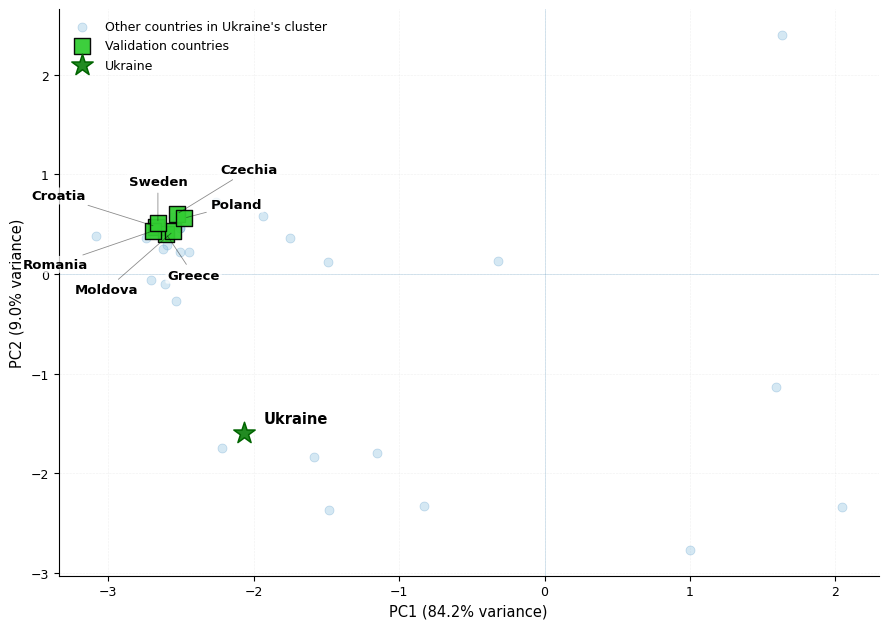

In [25]:
# ============================================================
# UKRAINE CLUSTER AND VALIDATION-COUNTRY SELECTION
# PCA visualization of the current weekly KMeans solution
# ============================================================

plt.close("all")

from sklearn.decomposition import PCA


# ============================================================
# 1. PCA of the current weekly feature space
# ============================================================

feature_cols = [
    c for c in features12.columns
    if c != "Country"
]

X = (
    features12[feature_cols]
    .astype(float)
    .copy()
)

countries = (
    features12["Country"]
    .astype(str)
    .to_numpy()
)

X_scaled = RobustScaler().fit_transform(X)

pca = PCA(
    n_components=2
)

X_pca = pca.fit_transform(
    X_scaled
)

explained = (
    pca.explained_variance_ratio_
    * 100
)


# ============================================================
# 2. Add current KMeans labels
# ============================================================

kmeans_labels = np.asarray(
    labels_store12["KMeans_k2"]
)

pca_df = pd.DataFrame({
    "Country": countries,
    "PC1": X_pca[:, 0],
    "PC2": X_pca[:, 1],
    "Cluster": kmeans_labels
})

ukraine_cluster = int(
    pca_df.loc[
        pca_df["Country"].eq("Ukraine"),
        "Cluster"
    ].iloc[0]
)

cluster_df = pca_df[
    pca_df["Cluster"].eq(ukraine_cluster)
].copy()

ukraine = pca_df[
    pca_df["Country"].eq("Ukraine")
].iloc[0]


# ============================================================
# 3. Validation countries
# ============================================================

validation_set = set(validation_countries)

validation_label_countries = [
    "Sweden",
    "Greece",
    "Croatia",
    "Romania",
    "Poland",
    "Czechia",
    "Moldova"
]

validation_label_set = set(validation_label_countries)

# Use pca_df here, not cluster_df, so every validation country is plotted
# if it exists in the PCA dataframe.
validation_df = pca_df[
    pca_df["Country"].isin(validation_set)
].copy()

other_cluster_members = cluster_df[
    (~cluster_df["Country"].isin(validation_set))
    &
    (~cluster_df["Country"].eq("Ukraine"))
].copy()

missing_from_pca = sorted(
    validation_set - set(validation_df["Country"])
)

validation_outside_ukraine_cluster = sorted(
    set(validation_df.loc[
        ~validation_df["Cluster"].eq(ukraine_cluster),
        "Country"
    ])
)


print(
    "Ukraine KMeans cluster:",
    ukraine_cluster
)

print(
    "Countries in Ukraine's cluster:",
    len(cluster_df)
)

print(
    "Validation countries expected:",
    sorted(validation_set)
)

print(
    "Validation countries plotted:",
    sorted(validation_df["Country"].tolist())
)

print(
    "Number of validation countries plotted:",
    len(validation_df)
)

print(
    "Labelled validation countries:",
    validation_label_countries
)

if missing_from_pca:
    print(
        "WARNING: validation countries not found in PCA dataframe:",
        missing_from_pca
    )

if validation_outside_ukraine_cluster:
    print(
        "NOTE: validation countries outside Ukraine's KMeans cluster:",
        validation_outside_ukraine_cluster
    )

print(
    f"PCA variance explained: "
    f"PC1 = {explained[0]:.1f}%, "
    f"PC2 = {explained[1]:.1f}%, "
    f"total = {explained[:2].sum():.1f}%"
)


# ============================================================
# 4. Display-only jitter for overlapping validation markers
# ============================================================

validation_df = validation_df.sort_values("Country").copy()

# These offsets only move the plotted validation squares slightly.
# The PCA coordinates themselves remain unchanged.
jitter_offsets = {
    "Croatia": (-0.035,  0.035),
    "Czechia": ( 0.000,  0.060),
    "Greece":  ( 0.035, -0.035),
    "Moldova": (-0.050, -0.035),
    "Poland":  ( 0.050,  0.020),
    "Romania": (-0.055, -0.010),
    "Sweden":  ( 0.020,  0.050),
}

validation_df["PC1_plot"] = validation_df.apply(
    lambda r: r["PC1"] + jitter_offsets.get(
        r["Country"],
        (0.0, 0.0)
    )[0],
    axis=1
)

validation_df["PC2_plot"] = validation_df.apply(
    lambda r: r["PC2"] + jitter_offsets.get(
        r["Country"],
        (0.0, 0.0)
    )[1],
    axis=1
)


# ============================================================
# 5. Figure
# ============================================================

fig_cluster, ax_cluster = plt.subplots(
    figsize=(9.0, 6.4)
)


# Countries from Ukraine's KMeans cluster, excluding Ukraine and validation countries.
ax_cluster.scatter(
    other_cluster_members["PC1"],
    other_cluster_members["PC2"],
    s=42,
    alpha=0.28,
    marker="o",
    color="#6baed6",
    edgecolor="#3182bd",
    linewidth=0.5,
    label="Other countries in Ukraine's cluster",
    zorder=2
)


# All validation countries, slightly jittered for visibility.
ax_cluster.scatter(
    validation_df["PC1_plot"],
    validation_df["PC2_plot"],
    s=135,
    marker="s",
    color="limegreen",
    edgecolor="black",
    linewidth=1.0,
    alpha=0.95,
    zorder=6,
    label="Validation countries"
)


# Ukraine.
ax_cluster.scatter(
    ukraine["PC1"],
    ukraine["PC2"],
    s=260,
    marker="*",
    color="forestgreen",
    edgecolor="darkgreen",
    linewidth=1.1,
    zorder=7,
    label="Ukraine"
)


# ============================================================
# 6. Labels
# ============================================================

label_offsets = {
    "Croatia": (-70, 22),
    "Romania": (-70, -24),
    "Sweden": (0, 30),
    "Poland": (38, 10),
    "Greece": (20, -30),
    "Czechia": (52, 32),
    "Moldova": (-48, -42),
}

label_df = validation_df[
    validation_df["Country"].isin(validation_label_set)
].copy()

for _, row in label_df.iterrows():

    dx, dy = label_offsets.get(
        row["Country"],
        (10, 10)
    )

    ax_cluster.annotate(
        row["Country"],
        (
            row["PC1_plot"],
            row["PC2_plot"]
        ),
        xytext=(dx, dy),
        textcoords="offset points",
        fontsize=9.5,
        fontweight="semibold",
        ha="center",
        va="center",
        arrowprops=dict(
            arrowstyle="-",
            linewidth=0.6,
            alpha=0.45
        ),
        bbox=dict(
            boxstyle="round,pad=0.15",
            facecolor="white",
            edgecolor="none",
            alpha=0.75
        ),
        zorder=8
    )


ax_cluster.annotate(
    "Ukraine",
    (
        ukraine["PC1"],
        ukraine["PC2"]
    ),
    xytext=(14, 10),
    textcoords="offset points",
    fontsize=10.5,
    fontweight="bold",
    ha="left",
    va="center",
    bbox=dict(
        boxstyle="round,pad=0.15",
        facecolor="white",
        edgecolor="none",
        alpha=0.80
    ),
    zorder=8
)


# ============================================================
# 7. Formatting
# ============================================================

ax_cluster.set_xlabel(
    f"PC1 ({explained[0]:.1f}% variance)",
    fontsize=10.5
)

ax_cluster.set_ylabel(
    f"PC2 ({explained[1]:.1f}% variance)",
    fontsize=10.5
)

ax_cluster.axhline(
    0,
    linewidth=0.6,
    alpha=0.20
)

ax_cluster.axvline(
    0,
    linewidth=0.6,
    alpha=0.20
)

ax_cluster.grid(
    True,
    linestyle="--",
    linewidth=0.45,
    alpha=0.18
)

ax_cluster.spines["top"].set_visible(False)
ax_cluster.spines["right"].set_visible(False)

ax_cluster.tick_params(
    axis="both",
    labelsize=9
)

ax_cluster.legend(
    frameon=False,
    fontsize=9,
    loc="upper left"
)

fig_cluster.tight_layout()


# ============================================================
# 8. Save
# ============================================================

fig_cluster.savefig(
    "ukraine_cluster_validation_selection.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [26]:
records = []

for country in validation_countries:
    cdf = weekly_df[weekly_df[country_col] == country].copy()
    for outcome_name, value_col in [("cases", case_col), ("deaths", death_col)]:
        values = cdf[value_col].to_numpy(dtype=float)

        # only evaluate where the underlying truth is observed
        finite = np.isfinite(values)
        n = len(values)

        for block_len in BLOCK_LENGTHS:
            if n < block_len + 20:
                continue

            # admissible start positions require a fully observed hidden block
            starts = []
            for s in range(5, n - block_len - 5):
                if finite[s:s+block_len].all():
                    starts.append(s)

            if len(starts) == 0:
                continue

            # spread positions across the series rather than using purely adjacent windows
            if len(starts) <= N_POSITIONS_PER_SERIES:
                chosen_starts = starts
            else:
                quantile_idx = np.linspace(0, len(starts)-1, N_POSITIONS_PER_SERIES).astype(int)
                chosen_starts = [starts[i] for i in quantile_idx]

            for start in chosen_starts:
                mask = np.zeros(n, dtype=bool)
                mask[start:start+block_len] = True
                y_true = values[mask]

                for method, func in RECONSTRUCTORS.items():
                    try:
                        y_pred = func(values, mask)
                        if len(y_pred) != len(y_true) or np.isnan(y_pred).any():
                            continue
                        mets = metric_bundle(y_true, y_pred, reference_values=values[finite])
                        records.append({
                            "country": country,
                            "outcome": outcome_name,
                            "block_length": block_len,
                            "start_index": int(start),
                            "start_week": cdf.iloc[start][date_col],
                            "end_week": cdf.iloc[start + block_len - 1][date_col],
                            "hidden_block_mean_truth": float(np.nanmean(y_true)),
                            "method": method,
                            **mets
                        })
                    except Exception as e:
                        records.append({
                            "country": country,
                            "outcome": outcome_name,
                            "block_length": block_len,
                            "start_index": int(start),
                            "start_week": cdf.iloc[start][date_col],
                            "end_week": cdf.iloc[start + block_len - 1][date_col],
                            "hidden_block_mean_truth": float(np.nanmean(y_true)),
                            "method": method,
                            "MAE": np.nan,
                            "RMSE": np.nan,
                            "sMAPE": np.nan,
                            "RMSE_log1p": np.nan,
                            "MASE": np.nan
                        })

repeated_block_results = pd.DataFrame(records)
repeated_block_results = repeated_block_results.dropna(subset=["RMSE"])

print(repeated_block_results.shape)
display(repeated_block_results.head())


(3360, 13)


,country,outcome,block_length,start_index,start_week,end_week,hidden_block_mean_truth,method,MAE,RMSE,sMAPE,RMSE_log1p,MASE
0,Sweden,cases,4,7,2020-02-24,2020-03-16,4.510577,linear,6.638234,6.784119,109.378886,1.280471,0.264996
1,Sweden,cases,4,7,2020-02-24,2020-03-16,4.510577,log-linear,2.150456,2.278889,77.855135,0.683150,0.085845
2,Sweden,cases,4,7,2020-02-24,2020-03-16,4.510577,smoothed-log-linear,2.170223,2.305513,78.010183,0.683853,0.086634
3,Sweden,cases,4,7,2020-02-24,2020-03-16,4.510577,seasonal-decomposition,24.091600,24.235992,150.986125,2.185308,0.961727
4,Sweden,cases,4,7,2020-02-24,2020-03-16,4.510577,seasonal-lag-52,194.093993,194.517290,190.978450,4.029224,7.748154


## Country-aware repeated-block summaries

Artificial gaps from the same country are correlated. The manuscript table and Figure 2 therefore use the same country-aware statistic: for each outcome, gap length and method, RMSE is first summarized within each country and then summarized across countries. Pooled experiment-row summaries are retained only as diagnostics.


In [27]:
def country_aware_metric_summary(df, group_cols=("outcome", "block_length", "method")):
    """Median of country-specific median metrics, with n reported explicitly."""
    group_cols = list(group_cols)

    country_level_metrics = (
        df
        .groupby(group_cols + ["country"], as_index=False)
        .agg(
            country_median_MAE=("MAE", "median"),
            country_median_RMSE=("RMSE", "median"),
            country_median_sMAPE=("sMAPE", "median"),
            country_median_RMSE_log1p=("RMSE_log1p", "median"),
            country_median_MASE=("MASE", "median"),
            n_experiments_country=("RMSE", "count")
        )
    )

    summary = (
        country_level_metrics
        .groupby(group_cols, as_index=False)
        .agg(
            median_MAE=("country_median_MAE", "median"),
            median_RMSE=("country_median_RMSE", "median"),
            median_sMAPE=("country_median_sMAPE", "median"),
            median_RMSE_log1p=("country_median_RMSE_log1p", "median"),
            median_MASE=("country_median_MASE", "median"),
            n_countries=("country", "nunique"),
            n_experiments=("n_experiments_country", "sum")
        )
        .sort_values(group_cols)
        .reset_index(drop=True)
    )

    return summary, country_level_metrics


repeated_block_country_summary, repeated_block_country_level = (
    country_aware_metric_summary(repeated_block_results)
)

# Diagnostic only: pooled over all artificial gaps, without country reweighting.
repeated_block_pooled_summary = (
    repeated_block_results
    .groupby(["outcome", "block_length", "method"], as_index=False)
    .agg(
        pooled_median_MAE=("MAE", "median"),
        pooled_median_RMSE=("RMSE", "median"),
        pooled_median_sMAPE=("sMAPE", "median"),
        pooled_median_RMSE_log1p=("RMSE_log1p", "median"),
        pooled_median_MASE=("MASE", "median"),
        n_experiments=("RMSE", "count")
    )
)

# Manuscript Table 4 uses this object.
table4_repeated_block_country_aware = (
    repeated_block_country_summary
    [[
        "outcome",
        "block_length",
        "method",
        "median_RMSE",
        "n_countries",
        "n_experiments"
    ]]
    .sort_values(["outcome", "block_length", "median_RMSE"])
    .reset_index(drop=True)
)

display(table4_repeated_block_country_aware)


,outcome,block_length,method,median_RMSE,n_countries,n_experiments
0,cases,4,smoothed-log-linear,2.722329,7,56
1,cases,4,log-linear,2.739998,7,56
2,cases,4,linear,3.129397,7,56
3,cases,4,GPR-Matern32,6.736903,7,56
4,cases,4,seasonal-decomposition,22.375866,7,56
5,cases,4,seasonal-lag-52,106.876901,7,56
6,cases,8,log-linear,7.030778,7,56
7,cases,8,smoothed-log-linear,7.105627,7,56
8,cases,8,GPR-Matern32,7.517355,7,56
9,cases,8,linear,8.198433,7,56


### Scale-sensitive validation metrics

Raw-scale RMSE is useful for absolute public-health burden, but it can be dominated by high-rate periods. The next table summarizes log1p-scale RMSE and MASE, which help check whether the method ranking is robust to scale.


In [28]:
scale_metric_summary = (
    repeated_block_results
    .groupby(['outcome', 'method'])[['RMSE', 'RMSE_log1p', 'MASE']]
    .median()
    .reset_index()
    .sort_values(['outcome', 'RMSE_log1p'])
)

display(scale_metric_summary)


,outcome,method,RMSE,RMSE_log1p,MASE
0,cases,GPR-Matern32,11.710414,0.370122,0.366306
2,cases,log-linear,11.143871,0.515395,0.368656
5,cases,smoothed-log-linear,11.265933,0.517895,0.369888
1,cases,linear,12.735522,0.567074,0.409667
3,cases,seasonal-decomposition,21.623126,0.890139,0.612448
4,cases,seasonal-lag-52,135.432494,1.614118,4.013002
6,deaths,GPR-Matern32,0.167114,0.111176,0.580344
8,deaths,log-linear,0.182619,0.115325,0.656092
11,deaths,smoothed-log-linear,0.185129,0.117563,0.685007
7,deaths,linear,0.181699,0.119189,0.685920


## Country-aware bootstrap intervals for repeated-block RMSE

The bootstrap below matches the Table 4 and Figure 2 estimand: median RMSE is computed within countries, then summarized across countries. This avoids treating repeated artificial gaps from the same country as fully independent observations.


In [29]:
FIG_BOOT_N = 1000
FIG_RANDOM_STATE = 42


def hierarchical_median_ci(
    df,
    outcome,
    block_length,
    method,
    n_boot=1000,
    random_state=42
):
    rng = np.random.default_rng(random_state)

    sdf = df[
        (df["outcome"] == outcome) &
        (df["block_length"] == block_length) &
        (df["method"] == method)
    ].copy()

    countries = sdf["country"].dropna().unique().tolist()

    if len(countries) == 0:
        return np.nan, np.nan, np.nan

    observed = float(
        sdf.groupby("country")["RMSE"].median().median()
    )

    boot_stats = []

    for _ in range(n_boot):
        sampled_countries = rng.choice(
            countries,
            size=len(countries),
            replace=True
        )

        sampled_country_medians = []

        for country in sampled_countries:
            values = (
                sdf.loc[sdf["country"] == country, "RMSE"]
                .dropna()
                .to_numpy(dtype=float)
            )
            if len(values) == 0:
                continue

            boot_country_values = rng.choice(
                values,
                size=len(values),
                replace=True
            )
            sampled_country_medians.append(np.median(boot_country_values))

        if sampled_country_medians:
            boot_stats.append(np.median(sampled_country_medians))

    if len(boot_stats) == 0:
        return observed, np.nan, np.nan

    ci_low, ci_high = np.percentile(boot_stats, [2.5, 97.5])
    return observed, float(ci_low), float(ci_high)


boot_rows = []

for outcome in sorted(repeated_block_results["outcome"].unique()):
    for block_length in BLOCK_LENGTHS:
        for method in RECONSTRUCTORS.keys():
            median_rmse, ci_low, ci_high = hierarchical_median_ci(
                repeated_block_results,
                outcome=outcome,
                block_length=block_length,
                method=method,
                n_boot=FIG_BOOT_N,
                random_state=FIG_RANDOM_STATE
            )
            boot_rows.append({
                "outcome": outcome,
                "block_length": block_length,
                "method": method,
                "median_RMSE": median_rmse,
                "CI95_low": ci_low,
                "CI95_high": ci_high,
            })

repeated_block_country_bootstrap_ci = pd.DataFrame(boot_rows)

# Keep the country and experiment counts beside the bootstrap intervals.
repeated_block_country_bootstrap_ci = (
    repeated_block_country_bootstrap_ci
    .merge(
        repeated_block_country_summary[
            ["outcome", "block_length", "method", "n_countries", "n_experiments"]
        ],
        on=["outcome", "block_length", "method"],
        how="left"
    )
    .sort_values(["outcome", "block_length", "median_RMSE"])
    .reset_index(drop=True)
)

display(repeated_block_country_bootstrap_ci)


,outcome,block_length,method,median_RMSE,CI95_low,CI95_high,n_countries,n_experiments
0,cases,4,smoothed-log-linear,2.722329,0.652692,15.555303,7,56
1,cases,4,log-linear,2.739998,0.651965,15.233991,7,56
2,cases,4,linear,3.129397,0.649825,16.686888,7,56
3,cases,4,GPR-Matern32,6.736903,0.675913,14.507817,7,56
4,cases,4,seasonal-decomposition,22.375866,4.557065,55.947735,7,56
5,cases,4,seasonal-lag-52,106.876901,26.075733,189.457195,7,56
6,cases,8,log-linear,7.030778,1.712661,43.673729,7,56
7,cases,8,smoothed-log-linear,7.105627,1.793839,44.515166,7,56
8,cases,8,GPR-Matern32,7.517355,1.410313,18.115789,7,56
9,cases,8,linear,8.198433,2.400219,25.609019,7,56


## Country-aware pairwise method comparisons

Pairwise comparisons are made on RMSE. The repeated-block experiment has multiple correlated hidden blocks within each country, so inference is based on country-level summaries and country-aware hierarchical bootstrap comparisons.


In [30]:
# ============================================================
# Country-level aggregation for valid paired inference
# ============================================================

country_level = (
    repeated_block_results
    .groupby(
        ["outcome", "country", "method"],
        as_index=False
    )
    .agg(
        median_RMSE=("RMSE", "median"),
        mean_RMSE=("RMSE", "mean"),
        n_experiments=("RMSE", "count")
    )
)

display(country_level.head())


# ============================================================
# Pairwise Wilcoxon tests at COUNTRY level
# ============================================================

test_rows = []

for outcome, odf in country_level.groupby("outcome"):

    wide = odf.pivot(
        index="country",
        columns="method",
        values="median_RMSE"
    )

    methods = [
        m for m in RECONSTRUCTORS
        if m in wide.columns
    ]

    for a, b in combinations(methods, 2):

        pair = wide[[a, b]].dropna()

        # Keep all available paired countries and report n explicitly.
        if len(pair) < 3:
            continue

        diff = pair[a] - pair[b]

        if np.allclose(diff, 0):
            stat = 0.0
            p = 1.0
        else:
            stat, p = wilcoxon(
                pair[a],
                pair[b],
                zero_method="wilcox",
                alternative="two-sided",
                method="auto"
            )

        test_rows.append({
            "outcome": outcome,
            "method_A": a,
            "method_B": b,
            "n_countries": len(pair),

            "median_country_RMSE_A":
                pair[a].median(),

            "median_country_RMSE_B":
                pair[b].median(),

            "median_paired_difference_A_minus_B":
                diff.median(),

            "W": stat,
            "p_value": p
        })


repeated_block_wilcoxon_country = pd.DataFrame(
    test_rows
)


# ============================================================
# Benjamini-Hochberg FDR correction
# separately for cases and deaths
# ============================================================

if not repeated_block_wilcoxon_country.empty:

    repeated_block_wilcoxon_country["p_FDR"] = np.nan
    repeated_block_wilcoxon_country["significant_FDR"] = False

    for outcome in repeated_block_wilcoxon_country["outcome"].unique():

        mask = (
            repeated_block_wilcoxon_country["outcome"]
            == outcome
        )

        _, adjusted, _, _ = multipletests(
            repeated_block_wilcoxon_country.loc[
                mask,
                "p_value"
            ].to_numpy(),
            alpha=0.05,
            method="fdr_bh"
        )

        repeated_block_wilcoxon_country.loc[
            mask,
            "p_FDR"
        ] = adjusted

        repeated_block_wilcoxon_country.loc[
            mask,
            "significant_FDR"
        ] = adjusted < 0.05


# ============================================================
# Display
# ============================================================

repeated_block_wilcoxon_country = (
    repeated_block_wilcoxon_country
    .sort_values(
        ["outcome", "p_FDR"]
    )
    .reset_index(drop=True)
)

display(
    repeated_block_wilcoxon_country[
        [
            "outcome",
            "method_A",
            "method_B",
            "n_countries",
            "median_country_RMSE_A",
            "median_country_RMSE_B",
            "median_paired_difference_A_minus_B",
            "W",
            "p_value",
            "p_FDR",
            "significant_FDR"
        ]
    ]
)


,outcome,country,method,median_RMSE,mean_RMSE,n_experiments
0,cases,Croatia,GPR-Matern32,12.805296,53.669719,40
1,cases,Croatia,linear,16.881478,60.784666,40
2,cases,Croatia,log-linear,17.707161,75.044969,40
3,cases,Croatia,seasonal-decomposition,18.846007,77.034458,40
4,cases,Croatia,seasonal-lag-52,156.808661,181.658953,40


,outcome,method_A,method_B,n_countries,median_country_RMSE_A,median_country_RMSE_B,median_paired_difference_A_minus_B,W,p_value,p_FDR,significant_FDR
0,cases,linear,seasonal-decomposition,7,15.090094,19.011729,-8.958201,0.0,0.015625,0.026042,True
1,cases,linear,seasonal-lag-52,7,15.090094,130.127775,-113.244079,0.0,0.015625,0.026042,True
2,cases,log-linear,seasonal-decomposition,7,12.670231,19.011729,-8.544846,0.0,0.015625,0.026042,True
3,cases,log-linear,seasonal-lag-52,7,12.670231,130.127775,-117.457544,0.0,0.015625,0.026042,True
4,cases,smoothed-log-linear,seasonal-decomposition,7,12.663501,19.011729,-8.529172,0.0,0.015625,0.026042,True
5,cases,smoothed-log-linear,seasonal-lag-52,7,12.663501,130.127775,-117.464273,0.0,0.015625,0.026042,True
6,cases,seasonal-decomposition,seasonal-lag-52,7,19.011729,130.127775,-103.971437,0.0,0.015625,0.026042,True
7,cases,seasonal-decomposition,GPR-Matern32,7,19.011729,12.805296,6.040711,0.0,0.015625,0.026042,True
8,cases,seasonal-lag-52,GPR-Matern32,7,130.127775,12.805296,116.752428,0.0,0.015625,0.026042,True
9,cases,linear,log-linear,7,15.090094,12.670231,1.431839,5.0,0.156250,0.213068,False


In [31]:
HIER_BOOT_N = 5000
HIER_BOOT_RANDOM_STATE = 42

rng_hier = np.random.default_rng(HIER_BOOT_RANDOM_STATE)


def hierarchical_bootstrap_pairwise(
    df,
    outcome,
    method_a,
    method_b,
    n_boot=5000,
    random_state=42
):
    rng = np.random.default_rng(random_state)

    odf = df[
        (df["outcome"] == outcome) &
        (df["method"].isin([method_a, method_b]))
    ].copy()

    # Wide format so each artificial gap has both methods side by side
    wide = odf.pivot_table(
        index=[
            "country",
            "block_length",
            "start_index"
        ],
        columns="method",
        values="RMSE",
        aggfunc="first"
    ).dropna(
        subset=[method_a, method_b]
    )

    countries = wide.index.get_level_values("country").unique().tolist()

    if len(countries) < 2:
        return None

    # Observed country-level paired differences
    observed_country_diffs = []

    for country in countries:
        cdf = wide.xs(
            country,
            level="country"
        )

        diff = (
            cdf[method_a] -
            cdf[method_b]
        )

        observed_country_diffs.append(
            np.median(diff)
        )

    observed_difference = float(
        np.median(observed_country_diffs)
    )

    boot_diffs = []

    for _ in range(n_boot):

        # Level 1: resample countries with replacement
        sampled_countries = rng.choice(
            countries,
            size=len(countries),
            replace=True
        )

        sampled_country_diffs = []

        for country in sampled_countries:

            cdf = wide.xs(
                country,
                level="country"
            )

            if len(cdf) == 0:
                continue

            # Level 2: resample repeated-block experiments
            idx = rng.integers(
                0,
                len(cdf),
                size=len(cdf)
            )

            boot_cdf = cdf.iloc[idx]

            diff = (
                boot_cdf[method_a] -
                boot_cdf[method_b]
            )

            sampled_country_diffs.append(
                np.median(diff)
            )

        if len(sampled_country_diffs) == 0:
            continue

        # Median across countries preserves equal country weighting
        boot_diffs.append(
            np.median(sampled_country_diffs)
        )

    boot_diffs = np.asarray(
        boot_diffs,
        dtype=float
    )

    ci_low, ci_high = np.percentile(
        boot_diffs,
        [2.5, 97.5]
    )

    # Bootstrap probability that A has lower RMSE than B
    prob_a_better = np.mean(
        boot_diffs < 0
    )

    prob_b_better = np.mean(
        boot_diffs > 0
    )

    return {
        "outcome": outcome,
        "method_A": method_a,
        "method_B": method_b,
        "n_countries": len(countries),
        "observed_median_difference_A_minus_B":
            observed_difference,
        "CI95_low": float(ci_low),
        "CI95_high": float(ci_high),
        "prob_A_lower_RMSE": float(prob_a_better),
        "prob_B_lower_RMSE": float(prob_b_better)
    }


# ============================================================
# Run all pairwise comparisons
# ============================================================

hier_rows = []

methods = list(RECONSTRUCTORS.keys())

for outcome in repeated_block_results["outcome"].unique():

    for a, b in combinations(methods, 2):

        result = hierarchical_bootstrap_pairwise(
            repeated_block_results,
            outcome=outcome,
            method_a=a,
            method_b=b,
            n_boot=HIER_BOOT_N,
            random_state=HIER_BOOT_RANDOM_STATE
        )

        if result is not None:
            hier_rows.append(result)


hierarchical_bootstrap_results = pd.DataFrame(
    hier_rows
)


# ============================================================
# Add an interpretation flag
# ============================================================

if not hierarchical_bootstrap_results.empty:

    hierarchical_bootstrap_results[
        "CI_excludes_zero"
    ] = (
        (
            hierarchical_bootstrap_results["CI95_low"] > 0
        )
        |
        (
            hierarchical_bootstrap_results["CI95_high"] < 0
        )
    )

    hierarchical_bootstrap_results[
        "direction"
    ] = np.where(
        hierarchical_bootstrap_results[
            "CI95_high"
        ] < 0,
        "A lower RMSE",
        np.where(
            hierarchical_bootstrap_results[
                "CI95_low"
            ] > 0,
            "B lower RMSE",
            "uncertain"
        )
    )


# ============================================================
# Display
# ============================================================

hierarchical_bootstrap_results = (
    hierarchical_bootstrap_results
    .sort_values(
        [
            "outcome",
            "CI_excludes_zero",
            "observed_median_difference_A_minus_B"
        ],
        ascending=[
            True,
            False,
            True
        ]
    )
    .reset_index(drop=True)
)

display(
    hierarchical_bootstrap_results[
        [
            "outcome",
            "method_A",
            "method_B",
            "n_countries",
            "observed_median_difference_A_minus_B",
            "CI95_low",
            "CI95_high",
            "prob_A_lower_RMSE",
            "prob_B_lower_RMSE",
            "CI_excludes_zero",
            "direction"
        ]
    ]
)

,outcome,method_A,method_B,n_countries,observed_median_difference_A_minus_B,CI95_low,CI95_high,prob_A_lower_RMSE,prob_B_lower_RMSE,CI_excludes_zero,direction
0,cases,smoothed-log-linear,seasonal-lag-52,7,-53.214978,-143.419740,-2.620693e+01,1.0000,0.0000,True,A lower RMSE
1,cases,log-linear,seasonal-lag-52,7,-53.202156,-144.117474,-2.623602e+01,1.0000,0.0000,True,A lower RMSE
2,cases,linear,seasonal-lag-52,7,-52.915763,-145.466945,-2.654871e+01,1.0000,0.0000,True,A lower RMSE
3,cases,seasonal-decomposition,seasonal-lag-52,7,-28.919025,-95.019470,-1.848353e+01,1.0000,0.0000,True,A lower RMSE
4,cases,log-linear,seasonal-decomposition,7,-5.011880,-7.943545,-2.455542e+00,1.0000,0.0000,True,A lower RMSE
5,cases,smoothed-log-linear,seasonal-decomposition,7,-4.973111,-7.937517,-2.417460e+00,1.0000,0.0000,True,A lower RMSE
6,cases,linear,seasonal-decomposition,7,-3.929023,-7.357268,-2.129775e+00,1.0000,0.0000,True,A lower RMSE
7,cases,log-linear,smoothed-log-linear,7,-0.011780,-0.041307,-3.935442e-03,0.9998,0.0002,True,A lower RMSE
8,cases,log-linear,GPR-Matern32,7,0.444338,0.133907,1.719619e+00,0.0016,0.9984,True,B lower RMSE
9,cases,smoothed-log-linear,GPR-Matern32,7,0.472908,0.142700,1.776761e+00,0.0008,0.9992,True,B lower RMSE


### Sensitivity analyses

These analyses report long-gap performance, performance for gaps starting in 2023 or later, and leave-one-country-out sensitivity for GPR comparisons. All repeated-block summaries use country-aware aggregation unless explicitly labelled as pooled diagnostics.


In [32]:
LONG_GAP_LENGTHS = [16, 24]
POST_2023_START = pd.Timestamp("2023-01-01")

long_gap_results = repeated_block_results[
    repeated_block_results["block_length"].isin(LONG_GAP_LENGTHS)
].copy()

long_gap_summary, long_gap_country_level = country_aware_metric_summary(
    long_gap_results
)
long_gap_summary = long_gap_summary.sort_values(
    ["outcome", "block_length", "median_RMSE"]
).reset_index(drop=True)

print("Supplementary long-gap summary: 16- and 24-week artificial gaps")
display(long_gap_summary)

post2023_results = repeated_block_results[
    repeated_block_results["start_week"] >= POST_2023_START
].copy()

post2023_summary, post2023_country_level = country_aware_metric_summary(
    post2023_results
)
post2023_summary = post2023_summary.sort_values(
    ["outcome", "block_length", "median_RMSE"]
).reset_index(drop=True)

print("Validation from 2023 onwards: artificial blocks starting in 2023 or later")
display(post2023_summary)


Supplementary long-gap summary: 16- and 24-week artificial gaps


,outcome,block_length,method,median_MAE,median_RMSE,median_sMAPE,median_RMSE_log1p,median_MASE,n_countries,n_experiments
0,cases,16,GPR-Matern32,10.261070,12.856851,61.967718,0.733434,0.403579,7,56
1,cases,16,log-linear,10.714844,14.351803,76.066513,0.817676,0.422555,7,56
2,cases,16,smoothed-log-linear,10.719047,14.355712,76.475456,0.819384,0.424933,7,56
3,cases,16,seasonal-decomposition,15.611937,19.944375,91.869176,0.989049,0.617812,7,56
4,cases,16,linear,18.892650,21.144500,86.588818,0.966350,0.565573,7,56
5,cases,16,seasonal-lag-52,96.663193,126.028224,116.945897,1.622012,4.839049,7,56
6,cases,24,GPR-Matern32,14.362832,17.676306,82.760994,1.043695,0.573358,7,56
7,cases,24,linear,20.771539,25.961082,79.148199,0.972304,0.709751,7,56
8,cases,24,log-linear,15.847604,26.692789,79.495970,0.949797,0.641062,7,56
9,cases,24,smoothed-log-linear,16.020604,26.893084,79.663191,0.951786,0.648060,7,56


Validation from 2023 onwards: artificial blocks starting in 2023 or later


,outcome,block_length,method,median_MAE,median_RMSE,median_sMAPE,median_RMSE_log1p,median_MASE,n_countries,n_experiments
0,cases,4,GPR-Matern32,0.397592,0.458936,18.608173,0.119566,0.015872,7,28
1,cases,4,smoothed-log-linear,0.444417,0.506705,17.956161,0.119262,0.019240,7,28
2,cases,4,log-linear,0.478556,0.582163,18.102987,0.130218,0.017553,7,28
3,cases,4,linear,0.552578,0.591511,19.529312,0.145966,0.020107,7,28
4,cases,4,seasonal-decomposition,2.289599,2.442278,47.544343,0.439668,0.114558,7,28
5,cases,4,seasonal-lag-52,15.992693,16.289651,132.863649,1.478569,0.725115,7,28
6,cases,8,GPR-Matern32,0.791422,1.024900,18.423851,0.177185,0.036415,7,28
7,cases,8,log-linear,0.913203,1.046247,28.661989,0.226928,0.043278,7,28
8,cases,8,smoothed-log-linear,0.937298,1.088315,29.341086,0.233955,0.044735,7,28
9,cases,8,linear,2.117700,2.457281,43.229565,0.312068,0.053013,7,28


In [33]:
# ============================================================
# Leave-one-country-out sensitivity for GPR comparisons
# ============================================================

def leave_one_country_out_gpr(
    df,
    outcome='cases',
    reference_method='GPR-Matern32',
    comparator_methods=None,
    block_lengths=None
):
    if comparator_methods is None:
        comparator_methods = [
            'linear',
            'log-linear',
            'smoothed-log-linear',
            'seasonal-decomposition',
            'seasonal-lag-52'
        ]

    odf = df[df['outcome'].eq(outcome)].copy()

    if block_lengths is not None:
        odf = odf[odf['block_length'].isin(block_lengths)].copy()

    wide = odf.pivot_table(
        index=['country', 'block_length', 'start_index'],
        columns='method',
        values='RMSE',
        aggfunc='first'
    )

    countries = sorted(wide.index.get_level_values('country').unique())
    rows = []

    for comparator in comparator_methods:
        if comparator not in wide.columns or reference_method not in wide.columns:
            continue

        pair = wide[[comparator, reference_method]].dropna()

        for left_out in ['none'] + countries:
            if left_out == 'none':
                sub = pair.copy()
            else:
                sub = pair[
                    pair.index.get_level_values('country') != left_out
                ].copy()

            if sub.empty:
                continue

            country_diffs = []
            for country in sorted(sub.index.get_level_values('country').unique()):
                cdf = sub.xs(country, level='country')
                diff = cdf[comparator] - cdf[reference_method]
                country_diffs.append(float(np.median(diff)))

            rows.append({
                'outcome': outcome,
                'block_lengths': 'all' if block_lengths is None else ','.join(map(str, block_lengths)),
                'comparator_minus_GPR': comparator,
                'left_out_country': left_out,
                'n_countries': len(country_diffs),
                'median_country_difference': float(np.median(country_diffs)),
                'GPR_lower_RMSE': bool(np.median(country_diffs) > 0)
            })

    return pd.DataFrame(rows)

loo_cases_all = leave_one_country_out_gpr(
    repeated_block_results,
    outcome='cases',
    block_lengths=None
)

loo_cases_long = leave_one_country_out_gpr(
    repeated_block_results,
    outcome='cases',
    block_lengths=LONG_GAP_LENGTHS
)

loo_deaths_all = leave_one_country_out_gpr(
    repeated_block_results,
    outcome='deaths',
    block_lengths=None
)

leave_one_country_out_gpr_results = pd.concat(
    [loo_cases_all, loo_cases_long, loo_deaths_all],
    ignore_index=True
)

print('Supplementary leave-one-country-out sensitivity for GPR comparisons:')
display(leave_one_country_out_gpr_results)

loo_summary = (
    leave_one_country_out_gpr_results
    .groupby(['outcome', 'block_lengths', 'comparator_minus_GPR'], as_index=False)
    .agg(
        n_leave_one_out_runs=('left_out_country', 'count'),
        n_support_GPR=('GPR_lower_RMSE', 'sum'),
        min_difference=('median_country_difference', 'min'),
        median_difference=('median_country_difference', 'median'),
        max_difference=('median_country_difference', 'max')
    )
)

print('Supplementary leave-one-country-out summary:')
display(loo_summary)


Supplementary leave-one-country-out sensitivity for GPR comparisons:


,outcome,block_lengths,comparator_minus_GPR,left_out_country,n_countries,median_country_difference,GPR_lower_RMSE
0,cases,all,linear,none,7,1.228557,True
1,cases,all,linear,Croatia,6,0.895770,True
2,cases,all,linear,Czechia,6,1.293473,True
3,cases,all,linear,Greece,6,0.895770,True
4,cases,all,linear,Moldova,6,0.895770,True
...,...,...,...,...,...,...,...
115,deaths,all,seasonal-lag-52,Greece,6,0.497044,True
116,deaths,all,seasonal-lag-52,Moldova,6,0.576677,True
117,deaths,all,seasonal-lag-52,Poland,6,0.576677,True
118,deaths,all,seasonal-lag-52,Romania,6,0.562670,True


Supplementary leave-one-country-out summary:


,outcome,block_lengths,comparator_minus_GPR,n_leave_one_out_runs,n_support_GPR,min_difference,median_difference,max_difference
0,cases,"16,24",linear,8,8,0.932339,1.363936,1.795532
1,cases,"16,24",log-linear,8,8,0.726626,0.877937,1.029247
2,cases,"16,24",seasonal-decomposition,8,8,3.018422,3.491685,3.964949
3,cases,"16,24",seasonal-lag-52,8,8,59.265320,63.072914,66.880508
4,cases,"16,24",smoothed-log-linear,8,8,0.736314,0.891978,1.047642
5,cases,all,linear,8,8,0.895770,1.094621,1.293473
6,cases,all,log-linear,8,8,0.414131,0.590613,0.767096
7,cases,all,seasonal-decomposition,8,8,5.444949,5.788561,6.132172
8,cases,all,seasonal-lag-52,8,8,52.078535,68.443021,84.807508
9,cases,all,smoothed-log-linear,8,8,0.433158,0.611196,0.789234


## Figure 2: repeated-block validation across gap lengths

The figure shows country-aware RMSE summaries with hierarchical bootstrap intervals.


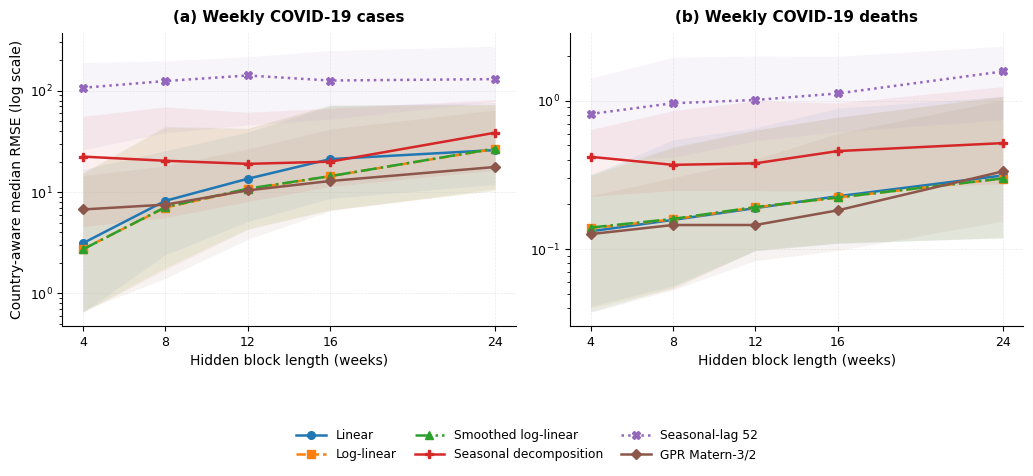

In [34]:
# ============================================================
# FIGURE 2: Repeated blocked validation across gap lengths
# Uses the same country-aware statistic as Table 4.
# ============================================================

plot_df = repeated_block_country_bootstrap_ci.copy()

method_order = [
    "linear",
    "log-linear",
    "smoothed-log-linear",
    "seasonal-decomposition",
    "seasonal-lag-52",
    "GPR-Matern32",
]

method_labels = {
    "linear": "Linear",
    "log-linear": "Log-linear",
    "smoothed-log-linear": "Smoothed log-linear",
    "seasonal-decomposition": "Seasonal decomposition",
    "seasonal-lag-52": "Seasonal-lag 52",
    "GPR-Matern32": "GPR Matern-3/2",
}

markers = {
    "linear": "o",
    "log-linear": "s",
    "smoothed-log-linear": "^",
    "seasonal-decomposition": "P",
    "seasonal-lag-52": "X",
    "GPR-Matern32": "D",
}

linestyles = {
    "linear": "-",
    "log-linear": "--",
    "smoothed-log-linear": "-.",
    "seasonal-decomposition": "-",
    "seasonal-lag-52": ":",
    "GPR-Matern32": "-",
}

fig, axes = plt.subplots(
    1,
    2,
    figsize=(12.4, 4.8),
    sharex=True
)

panel_settings = [
    ("cases", "(a) Weekly COVID-19 cases"),
    ("deaths", "(b) Weekly COVID-19 deaths"),
]

for ax, (outcome, title) in zip(axes, panel_settings):
    sdf = plot_df[plot_df["outcome"] == outcome].copy()

    for method in method_order:
        mdf = sdf[sdf["method"] == method].sort_values("block_length")
        if mdf.empty:
            continue

        x = mdf["block_length"].to_numpy(dtype=float)
        y = mdf["median_RMSE"].to_numpy(dtype=float)
        lower = mdf["CI95_low"].to_numpy(dtype=float)
        upper = mdf["CI95_high"].to_numpy(dtype=float)

        line, = ax.plot(
            x,
            y,
            marker=markers[method],
            linestyle=linestyles[method],
            linewidth=1.8,
            markersize=5.5,
            label=method_labels[method]
        )

        ax.fill_between(
            x,
            lower,
            upper,
            alpha=0.07,
            color=line.get_color(),
            linewidth=0
        )

    ax.set_yscale("log")
    ax.set_xticks(BLOCK_LENGTHS)
    ax.set_xlabel("Hidden block length (weeks)", fontsize=10)
    ax.set_title(title, fontsize=11, fontweight="bold", pad=8)
    ax.tick_params(axis="both", labelsize=9)
    ax.grid(True, which="major", linestyle="--", linewidth=0.5, alpha=0.25)
    ax.grid(False, which="minor")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].set_ylabel("Country-aware median RMSE (log scale)", fontsize=10)

handles, labels = axes[0].get_legend_handles_labels()
fig.legend(
    handles,
    labels,
    loc="lower center",
    bbox_to_anchor=(0.5, -0.035),
    ncol=3,
    frameon=False,
    fontsize=8.8,
    handlelength=2.4,
    columnspacing=1.5
)

fig.subplots_adjust(bottom=0.27, wspace=0.12)

plt.savefig(
    "repeated_block_validation_hierarchical.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()


## 8. Ukraine reporting gaps and applied reconstruction

This section compares WHO reports with national surveillance data and visualises and reconstructs selected reporting gaps in Ukraine.


In [35]:
# ============================================================
# UKRAINE REPORTING-GAP SETUP
# Cases and deaths are prepared together so the figures below
# use the same calendar, masks, methods, and gap definitions.
# ============================================================

import matplotlib.dates as mdates
import matplotlib.patches as mpatches


# ------------------------------------------------------------
# 1. Prepare Ukraine weekly series
# ------------------------------------------------------------

ua_final = (
    weekly[
        weekly["Country"].eq("Ukraine")
    ]
    .sort_values("week")
    .copy()
)

# Keep only complete Monday-Sunday weeks.
ua_final = ua_final[
    (ua_final["week"] >= pd.Timestamp("2020-01-06"))
    &
    (ua_final["week"] <= pd.Timestamp("2025-12-22"))
].copy()

ua_final = ua_final.reset_index(drop=True)

print(
    "Ukraine analysis period:",
    ua_final["week"].min().date(),
    "to",
    ua_final["week"].max().date()
)

print("Full joint missing weeks:", int(ua_final["joint_missing"].sum()))
print("Case-unreported weeks:", int((ua_final["case_report"] == 0).sum()))
print("Death-unreported weeks:", int((ua_final["death_report"] == 0).sum()))


# ------------------------------------------------------------
# 2. Reconstruction methods
# ------------------------------------------------------------

UKRAINE_METHODS = [
    "linear",
    "log-linear",
    "Kalman",
    "GPR Matern-3/2"
]

METHOD_LABELS = {
    "linear": "Linear",
    "log-linear": "Log-linear",
    "Kalman": "Kalman local level",
    "GPR Matern-3/2": "GPR Matern-3/2"
}

PRIMARY_CASE_METHOD = "GPR Matern-3/2"

# Deaths are a secondary sensitivity panel rather than an independently
# selected primary reconstruction target. Log-linear is used as a conservative
# monotone sensitivity reconstruction to avoid interpreting the GPR regression
# to the long-run mean as a primary mortality estimate.
PRIMARY_DEATH_METHOD = "log-linear"


def reconstruct_series(df, value_col, report_col):
    """Mask unreported weeks and reconstruct the full series with each method."""

    y = df[value_col].to_numpy(dtype=float)

    missing_mask = (
        (df[report_col].to_numpy() == 0)
        |
        (~np.isfinite(y))
    )

    masked = y.copy()
    masked[missing_mask] = np.nan

    predictions = {}

    for method in UKRAINE_METHODS:
        predictions[method] = np.asarray(
            MODELS[method](masked),
            dtype=float
        )

    return y, missing_mask, predictions


ua_cases_obs, ua_cases_mask, ua_cases_pred = reconstruct_series(
    ua_final,
    value_col="cases_per_100k",
    report_col="case_report"
)

ua_deaths_obs, ua_deaths_mask, ua_deaths_pred = reconstruct_series(
    ua_final,
    value_col="deaths_per_100k",
    report_col="death_report"
)


# ------------------------------------------------------------
# 3. Gap utilities
# ------------------------------------------------------------

GAP_COLUMNS = [
    "start_idx",
    "end_idx",
    "start_date",
    "end_date",
    "length"
]


def get_gap_runs(dates, mask):
    """Return contiguous weekly missing-reporting episodes."""

    dates = (
        pd.Series(pd.to_datetime(dates))
        .reset_index(drop=True)
    )

    mask = np.asarray(mask, dtype=bool)
    runs = []
    start = None

    for i, missing in enumerate(mask):
        if missing and start is None:
            start = i

        end_of_run = (
            start is not None
            and
            (
                (not missing)
                or
                (i == len(mask) - 1)
            )
        )

        if end_of_run:
            end = i if (missing and i == len(mask) - 1) else i - 1
            runs.append({
                "start_idx": start,
                "end_idx": end,
                "start_date": dates.iloc[start],
                "end_date": dates.iloc[end],
                "length": end - start + 1
            })
            start = None

    return pd.DataFrame(runs, columns=GAP_COLUMNS)


def get_internal_gap_runs(dates, mask, min_context=4):
    """Keep gaps with at least min_context observed weeks on both sides."""

    all_runs = get_gap_runs(dates, mask)

    if all_runs.empty:
        return pd.DataFrame(columns=GAP_COLUMNS)

    mask = np.asarray(mask, dtype=bool)
    internal_runs = []

    for _, row in all_runs.iterrows():
        start = int(row["start_idx"])
        end = int(row["end_idx"])

        left_values = mask[max(0, start - min_context):start]
        right_values = mask[end + 1:min(len(mask), end + 1 + min_context)]

        left_ok = (
            len(left_values) >= min_context
            and
            (~left_values).sum() >= min_context
        )

        right_ok = (
            len(right_values) >= min_context
            and
            (~right_values).sum() >= min_context
        )

        if left_ok and right_ok:
            internal_runs.append(row.to_dict())

    return pd.DataFrame(internal_runs, columns=GAP_COLUMNS)


def choose_longest_gap(gap_df):
    """Return the longest gap row or None."""

    if gap_df is None or gap_df.empty:
        return None

    return (
        gap_df
        .sort_values("length", ascending=False)
        .iloc[0]
    )


case_runs_all = get_gap_runs(ua_final["week"], ua_cases_mask)
death_runs_all = get_gap_runs(ua_final["week"], ua_deaths_mask)

case_runs_internal = get_internal_gap_runs(
    ua_final["week"],
    ua_cases_mask,
    min_context=4
)

death_runs_internal = get_internal_gap_runs(
    ua_final["week"],
    ua_deaths_mask,
    min_context=4
)

case_gap = choose_longest_gap(case_runs_internal)
death_gap = choose_longest_gap(death_runs_internal)

if case_gap is None:
    raise ValueError("No internal Ukraine case-reporting gap was found.")

case_gap_start = case_gap["start_date"]
case_gap_end = case_gap["end_date"]

if death_gap is not None:
    death_gap_start = death_gap["start_date"]
    death_gap_end = death_gap["end_date"]
else:
    death_gap_start = None
    death_gap_end = None

print("\nPrimary internal case gap:")
print(case_gap_start.date(), "to", case_gap_end.date(), f"({int(case_gap['length'])} weeks)")

print("\nInternal death gaps found:", len(death_runs_internal))
if death_gap is not None:
    print(death_gap_start.date(), "to", death_gap_end.date(), f"({int(death_gap['length'])} weeks)")
else:
    print("No internal death gap with sufficient two-sided context.")

print("\nAll case-reporting gaps:")
display(case_runs_all.sort_values("length", ascending=False).reset_index(drop=True))

print("\nAll death-reporting gaps:")
display(death_runs_all.sort_values("length", ascending=False).reset_index(drop=True))


Ukraine analysis period: 2020-01-06 to 2025-12-22
Full joint missing weeks: 26
Case-unreported weeks: 26
Death-unreported weeks: 40


e:\Covid\covid19_env\Lib\site-packages\statsmodels\base\model.py:607: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  warnings.warn("Maximum Likelihood optimization failed to "



Primary internal case gap:
2023-07-03 to 2023-10-23 (17 weeks)

Internal death gaps found: 0
No internal death gap with sufficient two-sided context.

All case-reporting gaps:


,start_idx,end_idx,start_date,end_date,length
0,182,198,2023-07-03,2023-10-23,17
1,0,8,2020-01-06,2020-03-02,9



All death-reporting gaps:


,start_idx,end_idx,start_date,end_date,length
0,182,208,2023-07-03,2024-01-01,27
1,0,8,2020-01-06,2020-03-02,9
2,210,213,2024-01-15,2024-02-05,4


### 8.0 External check against national surveillance

WHO values for Ukraine are compared with national routine-surveillance figures transcribed from official releases of the Public Health Center (PHC) and Ministry of Health of Ukraine. Two diagnostics are computed:

1. **Cumulative back-fill check**: whether the WHO cumulative total after the gap absorbs events that occurred during the gap. Agreement between the cumulative increase and the first post-gap report does not by itself establish whether historical values were revised or delayed events were redistributed across later weeks.
2. **Weekly comparison** of WHO and national counts for the weeks in which both sources are available (manuscript Table 6).

National figures are a plausibility reference, not ground truth. The value for the week beginning 25 September 2023 was reported as "more than 4,000" and is treated as a lower bound.

In [36]:
# ============================================================
# EXTERNAL CHECK AGAINST NATIONAL SURVEILLANCE (UKRAINE)
# National routine-surveillance values are transcribed from official
# releases of the Public Health Center (PHC) and Ministry of Health of
# Ukraine (manuscript references [57-60]). They are used as a
# plausibility reference, not as ground truth.
# ============================================================

# ------------------------------------------------------------
# 1. National weekly values (Monday-start weeks)
# ------------------------------------------------------------
# lower_bound=True marks values reported as "more than N".
phc_weekly = pd.DataFrame([
    # week start,   cases,  deaths, cases_lower_bound, source
    ("2023-09-18",  2500,   np.nan, False, "[59] Kuzin statement, 5 Oct 2023 (approx. 2,500)"),
    ("2023-09-25",  4000,   9,      True,  "[59] Kuzin statement, 5 Oct 2023 (>4,000)"),
    ("2023-10-23",  9480,   45,     False, "[57] PHC, epidemiological week 43"),
    ("2023-10-30",  9827,   51,     False, "[58] Cabinet of Ministers, 30 Oct - 5 Nov 2023"),
    ("2024-01-15",  3654,   30,     False, "[60] PHC, epidemiological week 3 of 2024"),
], columns=["week", "phc_cases", "phc_deaths", "cases_lower_bound", "source"])

phc_weekly["week"] = pd.to_datetime(phc_weekly["week"])
phc_weekly["Year"] = phc_weekly["week"].dt.year

ua_pop = (
    pop_long[pop_long["Country"].eq("Ukraine")][["Year", "Population"]]
)
phc_weekly = phc_weekly.merge(ua_pop, on="Year", how="left")
phc_weekly["phc_cases_per_100k"] = phc_weekly["phc_cases"] / phc_weekly["Population"] * 1e5
phc_weekly["phc_deaths_per_100k"] = phc_weekly["phc_deaths"] / phc_weekly["Population"] * 1e5

# National cumulative total for 2 Oct 2023 - 21 Jan 2024 (reference [60])
PHC_PERIOD_START = pd.Timestamp("2023-10-02")
PHC_PERIOD_END = pd.Timestamp("2024-01-21")
PHC_PERIOD_CASES = 130232
PHC_PERIOD_DEATHS = 650


# ------------------------------------------------------------
# 2. WHO cumulative back-fill diagnostic
# ------------------------------------------------------------
def cumulative_backfill_check(who_df, country, gap_start, gap_end):
    """Compare WHO cumulative totals on the last record before and the first
    record after a gap. If the cumulative increase equals the first post-gap
    report, events occurring during the gap were not added later."""
    d = who_df[who_df["Country"].eq(country)].sort_values("Date_reported")
    rows = []
    for new_col, cum_col, label in [("New_cases", "Cumulative_cases", "cases"),
                                    ("New_deaths", "Cumulative_deaths", "deaths")]:
        rec = d[d[new_col].notna()]
        before = rec[rec["Date_reported"] < gap_start].tail(1)
        after = rec[rec["Date_reported"] > gap_end + pd.Timedelta(days=6)].head(1)
        if before.empty or after.empty:
            continue
        cum_increase = float(after[cum_col].iloc[0] - before[cum_col].iloc[0])
        first_post = float(after[new_col].iloc[0])
        rows.append({
            "stream": label,
            "last_pre_gap_record": before["Date_reported"].iloc[0].date(),
            "pre_gap_weekday": before["Date_reported"].iloc[0].day_name(),
            "cumulative_before": float(before[cum_col].iloc[0]),
            "first_post_gap_record": after["Date_reported"].iloc[0].date(),
            "post_gap_weekday": after["Date_reported"].iloc[0].day_name(),
            "cumulative_after": float(after[cum_col].iloc[0]),
            "cumulative_increase": cum_increase,
            "first_post_gap_report": first_post,
            "gap_back_filled": cum_increase > first_post,
        })
    return pd.DataFrame(rows)


who_cumulative_check = cumulative_backfill_check(
    who, "Ukraine", case_gap_start, case_gap_end
)
print("WHO cumulative back-fill diagnostic for Ukraine's 2023 gap:")
display(who_cumulative_check)

ua_deaths_cum = who[who["Country"].eq("Ukraine") & who["Date_reported"].between("2023-07-02", "2024-03-31")]
print("Distinct WHO cumulative death values, Jul 2023 - Mar 2024:",
      sorted(ua_deaths_cum["Cumulative_deaths"].dropna().unique().tolist()))


# ------------------------------------------------------------
# 3. WHO vs national weekly comparison (manuscript Table 6)
# ------------------------------------------------------------
ua_who_weekly = (
    weekly[weekly["Country"].eq("Ukraine")]
    [["week", "New_cases", "New_deaths", "case_report", "death_report"]]
    .rename(columns={"New_cases": "who_cases", "New_deaths": "who_deaths"})
)

external_check_table = phc_weekly.merge(ua_who_weekly, on="week", how="left")
external_check_table["who_cases"] = external_check_table["who_cases"].where(
    external_check_table["case_report"].eq(1))
external_check_table["who_deaths"] = external_check_table["who_deaths"].where(
    external_check_table["death_report"].eq(1))
external_check_table["ratio_national_to_who_cases"] = (
    external_check_table["phc_cases"] / external_check_table["who_cases"]
)

# Alignment check: first post-gap WHO record against the preceding national week
first_post_who = external_check_table.loc[
    external_check_table["week"].eq(pd.Timestamp("2023-10-30")), "who_cases"].iloc[0]
prev_national = external_check_table.loc[
    external_check_table["week"].eq(pd.Timestamp("2023-10-23")), "phc_cases"].iloc[0]
print("Ratio national week 43 / first post-gap WHO record:", round(prev_national / first_post_who, 1))

who_period = ua_who_weekly[ua_who_weekly["week"].between(PHC_PERIOD_START, PHC_PERIOD_END)]
period_row = pd.DataFrame([{
    "week": "2023-10-02 to 2024-01-21 (16 weeks)",
    "who_cases": who_period.loc[who_period["case_report"].eq(1), "who_cases"].sum(),
    "phc_cases": PHC_PERIOD_CASES,
    "who_deaths": who_period.loc[who_period["death_report"].eq(1), "who_deaths"].sum(),
    "phc_deaths": PHC_PERIOD_DEATHS,
}])

table6_external_check = pd.concat([
    external_check_table[["week", "who_cases", "phc_cases", "who_deaths", "phc_deaths",
                          "ratio_national_to_who_cases", "phc_cases_per_100k",
                          "phc_deaths_per_100k", "cases_lower_bound", "source"]],
    period_row
], ignore_index=True)

print("\nTable 6. WHO and national weekly COVID-19 counts for Ukraine "
      "(NaN in WHO columns = no WHO record for that week):")
display(table6_external_check)

# Values quoted in the Figure 4 description
pre_gap_rate = ua_final.loc[ua_final["week"] < case_gap_start, "cases_per_100k"].dropna().iloc[-1]
post_gap_rate = ua_final.loc[ua_final["week"] > case_gap_end, "cases_per_100k"].dropna().iloc[0]
print("\nLast pre-gap WHO case rate per 100k:", round(pre_gap_rate, 2))
print("First post-gap WHO case rate per 100k:", round(post_gap_rate, 2))
print("National case rates per 100k:", phc_weekly[["week", "phc_cases_per_100k"]].round(2).to_dict("records"))
print("National death rates per 100k:", phc_weekly[["week", "phc_deaths_per_100k"]].round(3).to_dict("records"))



WHO cumulative back-fill diagnostic for Ukraine's 2023 gap:


,stream,last_pre_gap_record,pre_gap_weekday,cumulative_before,first_post_gap_record,post_gap_weekday,cumulative_after,cumulative_increase,first_post_gap_report,gap_back_filled
0,cases,2023-07-02,Sunday,5520483.0,2023-10-30,Monday,5520615.0,132.0,132.0,False
1,deaths,2023-07-02,Sunday,109918.0,2024-01-08,Monday,109918.0,0.0,0.0,False


Distinct WHO cumulative death values, Jul 2023 - Mar 2024: [109918, 109919, 109920]
Ratio national week 43 / first post-gap WHO record: 71.8

Table 6. WHO and national weekly COVID-19 counts for Ukraine (NaN in WHO columns = no WHO record for that week):


,week,who_cases,phc_cases,who_deaths,phc_deaths,ratio_national_to_who_cases,phc_cases_per_100k,phc_deaths_per_100k,cases_lower_bound,source
0,2023-09-18 00:00:00,NaN,2500,NaN,NaN,NaN,6.625529,NaN,False,"[59] Kuzin statement, 5 Oct 2023 (approx. 2,500)"
1,2023-09-25 00:00:00,NaN,4000,NaN,9.0,NaN,10.600846,0.023852,True,"[59] Kuzin statement, 5 Oct 2023 (>4,000)"
2,2023-10-23 00:00:00,NaN,9480,NaN,45.0,NaN,25.124006,0.119260,False,"[57] PHC, epidemiological week 43"
3,2023-10-30 00:00:00,132.0,9827,NaN,51.0,74.446970,26.043629,0.135161,False,"[58] Cabinet of Ministers, 30 Oct - 5 Nov 2023"
4,2024-01-15 00:00:00,401.0,3654,NaN,30.0,9.112219,9.651291,0.079239,False,"[60] PHC, epidemiological week 3 of 2024"
5,2023-10-02 to 2024-01-21 (16 weeks),6773.0,130232,0.0,650.0,NaN,NaN,NaN,NaN,NaN



Last pre-gap WHO case rate per 100k: 2.38
First post-gap WHO case rate per 100k: 0.35
National case rates per 100k: [{'week': Timestamp('2023-09-18 00:00:00'), 'phc_cases_per_100k': 6.63}, {'week': Timestamp('2023-09-25 00:00:00'), 'phc_cases_per_100k': 10.6}, {'week': Timestamp('2023-10-23 00:00:00'), 'phc_cases_per_100k': 25.12}, {'week': Timestamp('2023-10-30 00:00:00'), 'phc_cases_per_100k': 26.04}, {'week': Timestamp('2024-01-15 00:00:00'), 'phc_cases_per_100k': 9.65}]
National death rates per 100k: [{'week': Timestamp('2023-09-18 00:00:00'), 'phc_deaths_per_100k': nan}, {'week': Timestamp('2023-09-25 00:00:00'), 'phc_deaths_per_100k': 0.024}, {'week': Timestamp('2023-10-23 00:00:00'), 'phc_deaths_per_100k': 0.119}, {'week': Timestamp('2023-10-30 00:00:00'), 'phc_deaths_per_100k': 0.135}, {'week': Timestamp('2024-01-15 00:00:00'), 'phc_deaths_per_100k': 0.079}]


### 8.0b Panel-wide back-fill and catch-up check

This check asks whether long WHO reporting gaps in the 46-country panel are followed by observable catch-up in the first post-gap week. It uses the same internal-gap rule as the Ukraine application: at least four observed weeks before and after the gap. National Ukrainian data remain only a plausibility reference; the panel-wide check is based solely on WHO records.


In [37]:
# ============================================================
# PANEL-WIDE BACK-FILL AND CATCH-UP CHECK
# Uses the same internal-gap rule as the Ukraine application.
# ============================================================

BACKFILL_CONTEXT_WEEKS = 4
CATCHUP_POST_WEEKS = 4
MIN_EXPECTED_EVENTS = 10
CATCHUP_FULL = 0.5
CATCHUP_NONE = 0.2
LEVEL_SHIFT_FACTOR = 3.0

BACKFILL_STREAMS = {
    "cases": {
        "weekly": "New_cases",
        "report": "case_report"
    },
    "deaths": {
        "weekly": "New_deaths",
        "report": "death_report"
    },
}


def classify_panel_gap(
    cdf,
    row,
    value_col,
    context_weeks=BACKFILL_CONTEXT_WEEKS,
    post_weeks=CATCHUP_POST_WEEKS,
):
    """Classify whether the first post-gap week contains catch-up events.

    The baseline combines the four observed weeks before the gap and post-gap
    weeks 2-5. The first post-gap week is excluded from the baseline because
    it is the week being tested for catch-up.
    """

    start = int(row["start_idx"])
    end = int(row["end_idx"])

    y = cdf[value_col].to_numpy(dtype=float)

    pre = y[start - context_weeks:start]
    first_post = y[end + 1] if (end + 1) < len(y) else np.nan
    post = y[end + 2:end + 2 + post_weeks]

    baseline_values = np.r_[
        pre[np.isfinite(pre)],
        post[np.isfinite(post)]
    ]

    baseline = (
        float(np.nanmean(baseline_values))
        if len(baseline_values)
        else np.nan
    )

    expected_gap_events = (
        baseline * int(row["length"])
        if np.isfinite(baseline)
        else np.nan
    )

    excess_first_post = (
        first_post - baseline
        if np.isfinite(first_post) and np.isfinite(baseline)
        else np.nan
    )

    catchup_coverage = (
        excess_first_post / expected_gap_events
        if np.isfinite(expected_gap_events) and expected_gap_events > 0
        else np.nan
    )

    if (not np.isfinite(expected_gap_events)) or expected_gap_events < MIN_EXPECTED_EVENTS:
        catchup_status = "uninformative"
    elif catchup_coverage >= CATCHUP_FULL:
        catchup_status = "catch-up"
    elif catchup_coverage >= CATCHUP_NONE:
        catchup_status = "partial"
    else:
        catchup_status = "not recovered"

    pre_level = (
        float(np.nanmean(pre))
        if np.isfinite(pre).any()
        else np.nan
    )

    post_level = (
        float(np.nanmean(post))
        if np.isfinite(post).any()
        else np.nan
    )

    post_pre_level_ratio = (
        post_level / pre_level
        if np.isfinite(pre_level) and pre_level > 0
        else np.nan
    )

    level_shift = bool(
        np.isfinite(post_pre_level_ratio)
        and
        (
            (post_pre_level_ratio < 1 / LEVEL_SHIFT_FACTOR)
            or
            (post_pre_level_ratio > LEVEL_SHIFT_FACTOR)
        )
    )

    return {
        "baseline": baseline,
        "expected_gap_events": expected_gap_events,
        "first_post_gap_report": first_post,
        "excess_first_post": excess_first_post,
        "catchup_coverage": catchup_coverage,
        "catchup_status": catchup_status,
        "pre_level": pre_level,
        "post_level": post_level,
        "post_pre_level_ratio": post_pre_level_ratio,
        "level_shift": level_shift,
    }


panel_backfill_rows = []

for country, cdf in weekly.groupby("Country"):
    cdf = cdf.sort_values("week").reset_index(drop=True)

    for stream, cfg in BACKFILL_STREAMS.items():
        missing_mask = cdf[cfg["report"]].eq(0).to_numpy(dtype=bool)

        internal_gaps = get_internal_gap_runs(
            cdf["week"],
            missing_mask,
            min_context=BACKFILL_CONTEXT_WEEKS
        )

        if internal_gaps.empty:
            continue

        for _, gap_row in internal_gaps.iterrows():
            classification = classify_panel_gap(
                cdf,
                gap_row,
                cfg["weekly"]
            )

            panel_backfill_rows.append({
                "Country": country,
                "stream": stream,
                "start_date": gap_row["start_date"],
                "end_date": gap_row["end_date"],
                "length": int(gap_row["length"]),
                **classification
            })


panel_backfill_gap_level = pd.DataFrame(panel_backfill_rows)

panel_backfill_gap_level["long_gap"] = (
    panel_backfill_gap_level["length"] >= 5
)

panel_backfill_gap_level["informative_long_gap"] = (
    panel_backfill_gap_level["long_gap"]
    &
    panel_backfill_gap_level["catchup_status"].ne("uninformative")
)

panel_backfill_summary = pd.DataFrame([{
    "n_internal_gaps": int(len(panel_backfill_gap_level)),
    "n_countries_with_internal_gaps": int(panel_backfill_gap_level["Country"].nunique()),
    "n_long_gaps": int(panel_backfill_gap_level["long_gap"].sum()),
    "n_informative_long_gaps": int(panel_backfill_gap_level["informative_long_gap"].sum()),
    "n_informative_long_catchup": int(
        panel_backfill_gap_level.loc[
            panel_backfill_gap_level["informative_long_gap"],
            "catchup_status"
        ].eq("catch-up").sum()
    ),
    "n_informative_long_partial": int(
        panel_backfill_gap_level.loc[
            panel_backfill_gap_level["informative_long_gap"],
            "catchup_status"
        ].eq("partial").sum()
    ),
    "n_informative_long_not_recovered": int(
        panel_backfill_gap_level.loc[
            panel_backfill_gap_level["informative_long_gap"],
            "catchup_status"
        ].eq("not recovered").sum()
    ),
    "n_level_shifts": int(panel_backfill_gap_level["level_shift"].sum()),
}])

panel_backfill_status_by_stream = (
    panel_backfill_gap_level
    .groupby(["stream", "catchup_status"], as_index=False)
    .size()
    .rename(columns={"size": "n_gaps"})
    .sort_values(["stream", "catchup_status"])
)

ukraine_case_gap_start = pd.Timestamp("2023-07-03")
ukraine_case_gap_end = pd.Timestamp("2023-10-23")

panel_same_calendar_as_ukraine = (
    panel_backfill_gap_level[
        panel_backfill_gap_level["start_date"].eq(ukraine_case_gap_start)
        &
        panel_backfill_gap_level["end_date"].eq(ukraine_case_gap_end)
    ]
    .sort_values(["Country", "stream"])
    .reset_index(drop=True)
)






print("Panel-wide back-fill and catch-up summary:")
display(panel_backfill_summary)

print("Catch-up status by stream:")
display(panel_backfill_status_by_stream)

print("Gaps with the same calendar window as Ukraine's 2023 case gap:")
display(
    panel_same_calendar_as_ukraine[
        [
            "Country",
            "stream",
            "length",
            "catchup_status",
            "post_pre_level_ratio",
            "level_shift"
        ]
    ]
)



Panel-wide back-fill and catch-up summary:


,n_internal_gaps,n_countries_with_internal_gaps,n_long_gaps,n_informative_long_gaps,n_informative_long_catchup,n_informative_long_partial,n_informative_long_not_recovered,n_level_shifts
0,101,36,21,21,0,0,21,29


Catch-up status by stream:


,stream,catchup_status,n_gaps
0,cases,catch-up,3
1,cases,not recovered,36
2,cases,partial,7
3,cases,uninformative,7
4,deaths,catch-up,1
5,deaths,not recovered,17
6,deaths,partial,4
7,deaths,uninformative,26


Gaps with the same calendar window as Ukraine's 2023 case gap:


,Country,stream,length,catchup_status,post_pre_level_ratio,level_shift
0,Austria,cases,17,not recovered,0.116545,True
1,Ukraine,cases,17,not recovered,0.369451,False


### 8.1 Reporting-gap timeline for cases and deaths

The timeline shows missing weeks in Ukraine’s case and death reporting series.


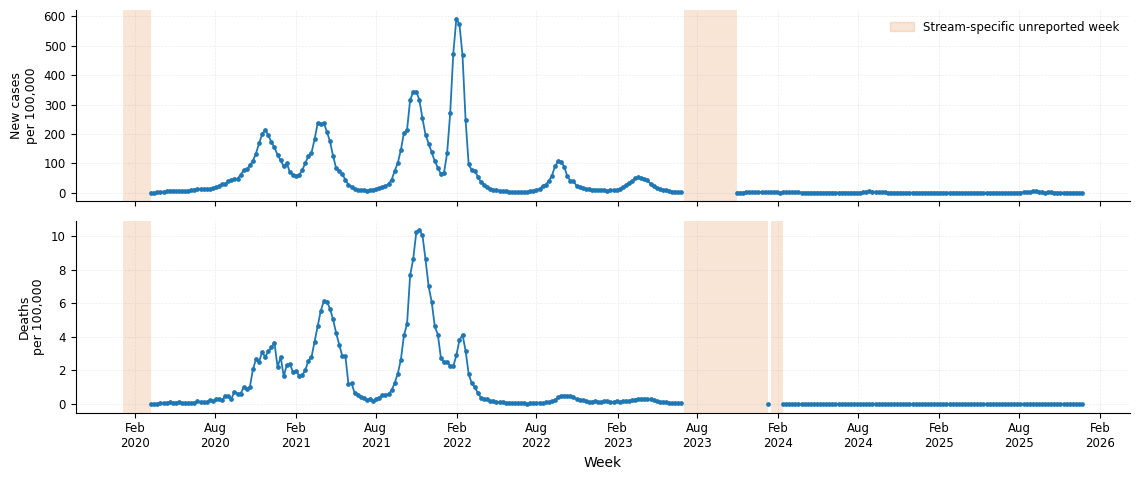

In [38]:
# ============================================================
# FIGURE: UKRAINE REPORTING-GAP TIMELINE
# Saves PNG only.
# ============================================================

import matplotlib.lines as mlines
import matplotlib.patches as mpatches

plot_df = ua_final.copy()
plot_df["case_missing"] = ua_cases_mask.astype(int)
plot_df["death_missing"] = ua_deaths_mask.astype(int)


def missing_segments(df, flag_col):
    runs = get_gap_runs(
        df["week"],
        df[flag_col].to_numpy(dtype=bool)
    )

    if runs.empty:
        return runs

    runs = runs.copy()
    runs["end_plot"] = runs["end_date"] + pd.Timedelta(days=7)

    return runs


case_missing_runs = missing_segments(plot_df, "case_missing")
death_missing_runs = missing_segments(plot_df, "death_missing")

fig, axes = plt.subplots(
    2,
    1,
    figsize=(11.5, 4.9),
    sharex=True,
    gridspec_kw={"height_ratios": [1, 1]}
)

timeline_specs = [
    ("New cases", "cases_per_100k", case_missing_runs, axes[0]),
    ("Deaths", "deaths_per_100k", death_missing_runs, axes[1]),
]

missing_color = "#d95f02"
primary_gap_color = "#6a3d9a"
observed_color = "#1f77b4"

for label, value_col, runs, ax in timeline_specs:
    ax.plot(
        plot_df["week"],
        plot_df[value_col],
        color=observed_color,
        linewidth=1.3,
        marker="o",
        markersize=2.4
    )

    for _, row in runs.iterrows():
        ax.axvspan(
            row["start_date"],
            row["end_plot"],
            color=missing_color,
            alpha=0.16,
            linewidth=0
        )

    ax.set_ylabel(
        f"{label}\nper 100,000",
        fontsize=9
    )

    ax.grid(
        True,
        linestyle="--",
        linewidth=0.5,
        alpha=0.25
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.tick_params(axis="both", labelsize=8.5)




axes[1].set_xlabel("Week", fontsize=10)
axes[1].xaxis.set_major_locator(mdates.MonthLocator(interval=6))
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))

axes[0].legend(
    handles=[
        mpatches.Patch(
            color=missing_color,
            alpha=0.16,
            label="Stream-specific unreported week"
        ),
    
    ],
    frameon=False,
    fontsize=8.5,
    loc="upper right"
)

fig.tight_layout()

plt.savefig(
    "ukraine_reporting_gaps_timeline_cases_deaths.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

### 8.2 Reconstruction of Ukraine's internal case-reporting gap

This is the primary applied reconstruction. The case gap is reconstructed only where an internal reporting gap has observed context on both sides. Boundary gaps remain unfilled.

Figure 4 overlays the national surveillance values from Section 8.0 (open black squares; the upward arrow marks the lower-bound value for the week beginning 25 September 2023).

Case gap: 2023-07-03 00:00:00 to 2023-10-23 00:00:00
Death gap: 2023-07-03 00:00:00 to 2024-01-01 00:00:00
Plot window: 2023-04-10 00:00:00 to 2024-03-25 00:00:00
Case GPR fitted kernel: 0.984**2 * Matern(length_scale=13.6, nu=1.5) + WhiteKernel(noise_level=0.00223)
Death GPR fitted kernel: 0.992**2 * Matern(length_scale=13.5, nu=1.5) + WhiteKernel(noise_level=0.00557)


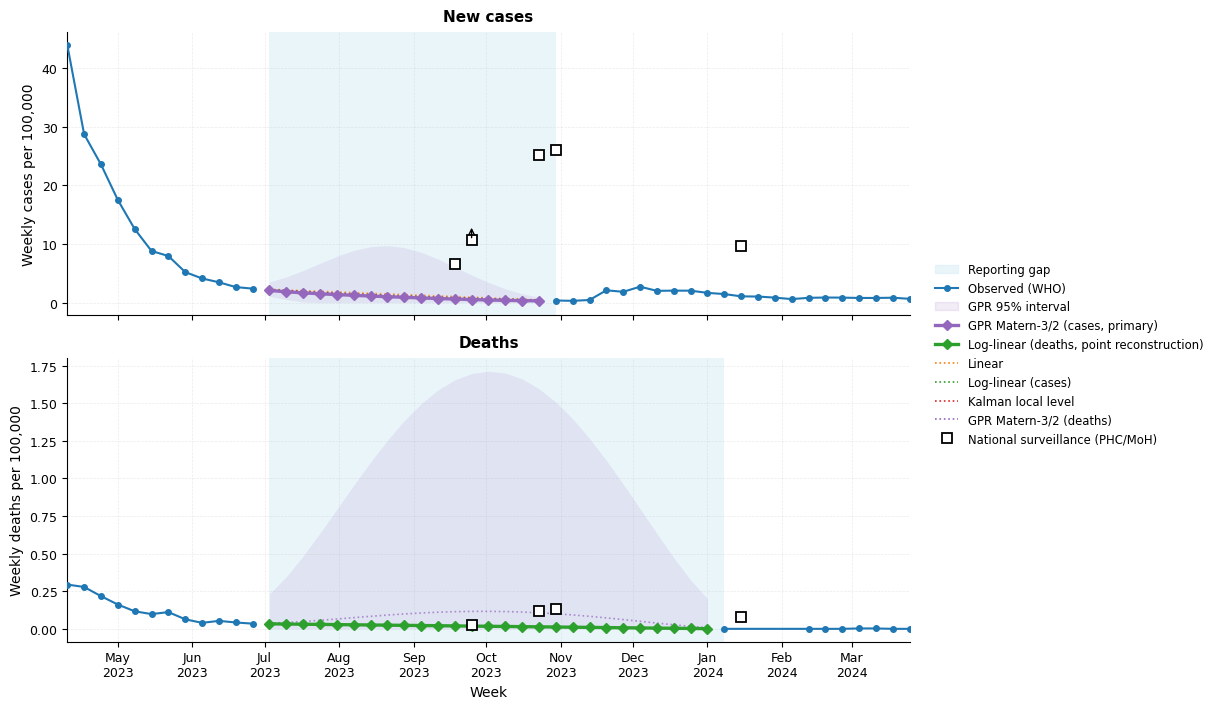

In [39]:
# ============================================================
# FIGURE: UKRAINE CASE AND DEATH GAP RECONSTRUCTION
# Saves PNG only.
# ============================================================

plt.close("all")

CONTEXT_WEEKS = 12

dates = ua_final["week"]


# ============================================================
# 1. Gap masks
# ============================================================

primary_case_gap_start = case_gap_start
primary_case_gap_end = case_gap_end

primary_case_gap_mask = (
    (ua_final["week"] >= primary_case_gap_start)
    &
    (ua_final["week"] <= primary_case_gap_end)
).to_numpy()


# Deaths are shown over their own longer stream-specific interruption
# as a secondary sensitivity panel.
primary_death_gap_start = pd.Timestamp("2023-07-03")
primary_death_gap_end = pd.Timestamp("2024-01-01")

primary_death_gap_mask = (
    (ua_final["week"] >= primary_death_gap_start)
    &
    (ua_final["week"] <= primary_death_gap_end)
).to_numpy()


window_start = min(
    primary_case_gap_start,
    primary_death_gap_start
) - pd.Timedelta(weeks=CONTEXT_WEEKS)

window_end = max(
    primary_case_gap_end,
    primary_death_gap_end
) + pd.Timedelta(weeks=CONTEXT_WEEKS)

window_mask = (
    (ua_final["week"] >= window_start)
    &
    (ua_final["week"] <= window_end)
).to_numpy()


print("Case gap:", primary_case_gap_start, "to", primary_case_gap_end)
print("Death gap:", primary_death_gap_start, "to", primary_death_gap_end)
print("Plot window:", window_start, "to", window_end)


# ============================================================
# 2. Primary methods and styles
# ============================================================

PRIMARY_CASE_METHOD = "GPR Matern-3/2"

# Deaths are not an independently selected primary death-gap reconstruction.
# Log-linear is highlighted as the conservative secondary point reconstruction.
PRIMARY_DEATH_METHOD = "log-linear"


UKRAINE_METHODS = [
    "linear",
    "log-linear",
    "Kalman",
    "GPR Matern-3/2"
]

METHOD_LABELS = {
    "linear": "Linear",
    "log-linear": "Log-linear",
    "Kalman": "Kalman local level",
    "GPR Matern-3/2": "GPR Matern-3/2"
}

method_styles = {
    "linear": {
        "color": "#ff7f0e"
    },
    "log-linear": {
        "color": "#2ca02c"
    },
    "Kalman": {
        "color": "#d62728"
    },
    "GPR Matern-3/2": {
        "color": "#9467bd"
    }
}

observed_color = "#1f77b4"
gap_color = "#d9edf7"


# ============================================================
# 3. Store reconstructed series in ua_final
# ============================================================

cases_reconstructed_primary = ua_cases_obs.copy()

cases_reconstructed_primary[primary_case_gap_mask] = (
    ua_cases_pred[PRIMARY_CASE_METHOD][primary_case_gap_mask]
)

ua_final["cases_per_100k_reconstructed"] = (
    cases_reconstructed_primary
)


deaths_reconstructed_secondary = ua_deaths_obs.copy()

deaths_reconstructed_secondary[primary_death_gap_mask] = (
    ua_deaths_pred[PRIMARY_DEATH_METHOD][primary_death_gap_mask]
)

ua_final["deaths_per_100k_reconstructed_secondary"] = (
    deaths_reconstructed_secondary
)


# ============================================================
# 4. GPR predictive intervals
# ============================================================

def gpr_prediction_interval(y, missing_mask):

    y = np.asarray(
        y,
        dtype=float
    )

    missing_mask = np.asarray(
        missing_mask,
        dtype=bool
    )

    x = np.arange(
        len(y)
    ).reshape(-1, 1)

    obs = (
        np.isfinite(y)
        &
        (~missing_mask)
    )

    z = np.log1p(
        np.clip(
            y,
            0,
            None
        )
    )

    kernel = (
        C(
            GPR_CONSTANT_VALUE,
            GPR_CONSTANT_BOUNDS
        )
        *
        Matern(
            length_scale=GPR_LENGTH_SCALE,
            length_scale_bounds=GPR_LENGTH_SCALE_BOUNDS,
            nu=1.5
        )
        +
        WhiteKernel(
            noise_level=0.05,
            noise_level_bounds=(1e-5, 10)
        )
    )

    gp = GaussianProcessRegressor(
        kernel=kernel,
        normalize_y=True,
        random_state=RANDOM_STATE,
        n_restarts_optimizer=GPR_N_RESTARTS
    )

    gp.fit(
        x[obs],
        z[obs]
    )

    z_mean, z_std = gp.predict(
        x,
        return_std=True
    )

    mean = np.expm1(
        z_mean
    )

    lower = np.expm1(
        z_mean - 1.96 * z_std
    )

    upper = np.expm1(
        z_mean + 1.96 * z_std
    )

    mean = np.clip(
        mean,
        0,
        None
    )

    lower = np.clip(
        lower,
        0,
        None
    )

    upper = np.clip(
        upper,
        0,
        None
    )

    return mean, lower, upper, gp.kernel_


cases_gpr_mean, cases_gpr_low, cases_gpr_high, cases_gpr_kernel = (
    gpr_prediction_interval(
        ua_cases_obs,
        primary_case_gap_mask
    )
)

deaths_gpr_mean, deaths_gpr_low, deaths_gpr_high, deaths_gpr_kernel = (
    gpr_prediction_interval(
        ua_deaths_obs,
        primary_death_gap_mask
    )
)

print("Case GPR fitted kernel:", cases_gpr_kernel)
print("Death GPR fitted kernel:", deaths_gpr_kernel)


# ============================================================
# 5. Figure setup
# ============================================================

fig, axes = plt.subplots(
    2,
    1,
    figsize=(11.2, 7.2),
    sharex=True,
    gridspec_kw={
        "height_ratios": [1, 1]
    }
)


panel_specs = [
    {
        "ax": axes[0],
        "title": "New cases",
        "observed": ua_cases_obs,
        "predictions": ua_cases_pred,
        "primary_method": PRIMARY_CASE_METHOD,
        "gap_start": primary_case_gap_start,
        "gap_end": primary_case_gap_end,
        "gap_mask": primary_case_gap_mask,
        "ylabel": "Weekly cases per 100,000",
        "gpr_low": cases_gpr_low,
        "gpr_high": cases_gpr_high,
    },
    {
        "ax": axes[1],
        "title": "Deaths",
        "observed": ua_deaths_obs,
        "predictions": ua_deaths_pred,
        "primary_method": PRIMARY_DEATH_METHOD,
        "gap_start": primary_death_gap_start,
        "gap_end": primary_death_gap_end,
        "gap_mask": primary_death_gap_mask,
        "ylabel": "Weekly deaths per 100,000",
        "gpr_low": deaths_gpr_low,
        "gpr_high": deaths_gpr_high,
    }
]


# ============================================================
# 6. Helper for observed segments
# ============================================================

def plot_observed_without_crossing_gap(
    ax,
    dates,
    observed,
    window_mask,
    gap_start,
    gap_end
):

    observed = np.asarray(
        observed,
        dtype=float
    )

    before_gap = (
        window_mask
        &
        np.isfinite(observed)
        &
        (dates < gap_start)
    )

    after_gap = (
        window_mask
        &
        np.isfinite(observed)
        &
        (dates > gap_end)
    )

    for mask in [before_gap, after_gap]:

        ax.plot(
            dates[mask],
            observed[mask],
            marker="o",
            markersize=4,
            linewidth=1.5,
            color=observed_color,
            zorder=4
        )


# ============================================================
# 7. Plot panels
# ============================================================

for spec in panel_specs:

    ax = spec["ax"]

    ax.axvspan(
        spec["gap_start"],
        spec["gap_end"] + pd.Timedelta(days=7),
        color=gap_color,
        alpha=0.55,
        linewidth=0,
        zorder=0
    )

    plot_observed_without_crossing_gap(
        ax=ax,
        dates=dates,
        observed=spec["observed"],
        window_mask=window_mask,
        gap_start=spec["gap_start"],
        gap_end=spec["gap_end"]
    )

    # GPR interval
    ax.fill_between(
        dates[spec["gap_mask"]],
        spec["gpr_low"][spec["gap_mask"]],
        spec["gpr_high"][spec["gap_mask"]],
        color=method_styles["GPR Matern-3/2"]["color"],
        alpha=0.12,
        linewidth=0,
        zorder=1
    )

    # Reconstruction methods
    for method in UKRAINE_METHODS:

        pred = np.asarray(
            spec["predictions"][method],
            dtype=float
        )

        color = method_styles[method]["color"]

        if method == spec["primary_method"]:

            ax.plot(
                dates[spec["gap_mask"]],
                pred[spec["gap_mask"]],
                linestyle="-",
                linewidth=2.4,
                marker="D",
                markersize=4.8,
                color=color,
                alpha=0.98,
                zorder=5
            )

        else:

            ax.plot(
                dates[spec["gap_mask"]],
                pred[spec["gap_mask"]],
                linestyle=":",
                linewidth=1.2,
                marker=None,
                color=color,
                alpha=0.70,
                zorder=3
            )

    ax.set_title(
        spec["title"],
        fontsize=11,
        fontweight="bold",
        pad=8
    )

    ax.set_ylabel(
        spec["ylabel"],
        fontsize=10
    )

    ax.grid(
        True,
        linestyle="--",
        linewidth=0.5,
        alpha=0.25
    )

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

    ax.tick_params(
        axis="both",
        labelsize=9
    )


# ============================================================
# 7b. National surveillance overlay (external check, Section 4.4)
# ============================================================

phc_marker_style = dict(
    marker="s",
    markersize=6.5,
    markerfacecolor="white",
    markeredgecolor="black",
    markeredgewidth=1.3,
    linestyle="none",
    zorder=7
)

phc_in_window = phc_weekly[
    (phc_weekly["week"] >= window_start) & (phc_weekly["week"] <= window_end)
]

for ax, col in [(axes[0], "phc_cases_per_100k"), (axes[1], "phc_deaths_per_100k")]:
    pts = phc_in_window[phc_in_window[col].notna()]
    ax.plot(pts["week"], pts[col], **phc_marker_style)

    # Mark the lower-bound value (">4,000" cases) with an upward arrow
    if col == "phc_cases_per_100k":
        lb = pts[pts["cases_lower_bound"]]
        for _, r in lb.iterrows():
            ax.annotate(
                "",
                xy=(r["week"], r[col] * 1.25),
                xytext=(r["week"], r[col]),
                arrowprops=dict(arrowstyle="->", color="black", lw=1.0),
                zorder=7
            )

# ============================================================
# 8. Shared legend
# Primary methods differ by panel: GPR for cases, log-linear for deaths.
# Each is shown with the solid line and diamond markers used in its panel.
# ============================================================

legend_handles = [
    mpatches.Patch(
        color=gap_color,
        alpha=0.55,
        label="Reporting gap"
    ),
    mlines.Line2D(
        [],
        [],
        color=observed_color,
        marker="o",
        linestyle="-",
        linewidth=1.5,
        markersize=4,
        label="Observed (WHO)"
    ),
    mpatches.Patch(
        color=method_styles["GPR Matern-3/2"]["color"],
        alpha=0.12,
        label="GPR 95% interval"
    ),
    mlines.Line2D(
        [],
        [],
        color=method_styles["GPR Matern-3/2"]["color"],
        linestyle="-",
        marker="D",
        linewidth=2.4,
        markersize=4.8,
        label="GPR Matern-3/2 (cases, primary)"
    ),
    mlines.Line2D(
        [],
        [],
        color=method_styles["log-linear"]["color"],
        linestyle="-",
        marker="D",
        linewidth=2.4,
        markersize=4.8,
        label="Log-linear (deaths, point reconstruction)"
    ),
    mlines.Line2D(
        [],
        [],
        color=method_styles["linear"]["color"],
        linestyle=":",
        linewidth=1.2,
        label="Linear"
    ),
    mlines.Line2D(
        [],
        [],
        color=method_styles["log-linear"]["color"],
        linestyle=":",
        linewidth=1.2,
        label="Log-linear (cases)"
    ),
    mlines.Line2D(
        [],
        [],
        color=method_styles["Kalman"]["color"],
        linestyle=":",
        linewidth=1.2,
        label="Kalman local level"
    ),
    mlines.Line2D(
        [],
        [],
        color=method_styles["GPR Matern-3/2"]["color"],
        linestyle=":",
        linewidth=1.2,
        label="GPR Matern-3/2 (deaths)"
    ),
    mlines.Line2D(
        [],
        [],
        marker="s",
        markersize=6.5,
        markerfacecolor="white",
        markeredgecolor="black",
        markeredgewidth=1.3,
        linestyle="none",
        label="National surveillance (PHC/MoH)"
    ),
]

fig.legend(
    handles=legend_handles,
    frameon=False,
    fontsize=8.4,
    loc="center left",
    bbox_to_anchor=(0.83, 0.50)
)


# ============================================================
# 9. Axes and save
# ============================================================

axes[1].set_xlabel(
    "Week",
    fontsize=10
)

axes[1].set_xlim(
    window_start,
    window_end
)

axes[1].xaxis.set_major_locator(
    mdates.MonthLocator(interval=1)
)

axes[1].xaxis.set_major_formatter(
    mdates.DateFormatter("%b\n%Y")
)

fig.tight_layout(
    rect=[0, 0, 0.83, 1]
)

plt.savefig(
    "ukraine_case_death_gap_reconstruction_combined.png",
    dpi=600,
    bbox_inches="tight"
)

plt.show()

In [40]:
ukraine_cluster = int(
    cluster_feature_profile.loc[
        cluster_feature_profile["Country"].eq("Ukraine"),
        "cluster"
    ].iloc[0]
)

recent_zero_missing = (
    cluster_feature_profile.loc[
        (cluster_feature_profile["cluster"].eq(ukraine_cluster))
        & (cluster_feature_profile["recent_missing_rate_52w"].eq(0)),
        ["Country", "recent_missing_rate_52w", "total_missing_weeks"]
    ]
    .sort_values("Country")
)

display(recent_zero_missing)
print("Number of countries:", len(recent_zero_missing))

,Country,recent_missing_rate_52w,total_missing_weeks
3,Austria,0.0,24
5,Belgium,0.0,7
6,Bosnia and Herzegovina,0.0,12
8,Croatia,0.0,7
9,Cyprus,0.0,36
10,Czechia,0.0,8
11,Denmark,0.0,11
12,Estonia,0.0,9
13,Finland,0.0,37
16,Germany,0.0,67


Number of countries: 29
